# Семинар 5-6. Решающие деревья, случайный лес и градиентный бустинг

**Дисциплина «ИИ и машинное обучение»** · НИУ ВШЭ, Высшая школа бизнеса

Магистратура «Бизнес-аналитика и цифровые решения в финансах»

Семинар идёт по моделям: сначала одно решающее дерево, затем случайный
лес, затем градиентный бустинг. Для каждой модели разбираем, как с ней
работать и что делают её главные параметры, а сильные и слабые стороны
показываем на тех данных, где они видны лучше всего: медицинская
страховка (1338 клиентов), звонки банка (45 тысяч), заявки сотрудников на
доступ (33 тысячи, признаки с тысячами значений) и задержки рейсов
(540 тысяч). В конце — когда какую модель и какую библиотеку бустинга
выбирать: LightGBM, XGBoost, CatBoost или HistGradientBoosting из
`scikit-learn`.

| Часть | О чём |
|---|---|
| 1 | **Решающее дерево.** Как оно обучается и что хранит; какие сочетания признаков находит само; глубина и размер листа; неустойчивость, постоянный прогноз за пределами обучающих данных, пропуски. Данные — медицинская страховка |
| 2 | **Случайный лес.** Почему он устойчивее дерева; число деревьев, размер листа и доля признаков в узле; оценка качества OOB без отдельной выборки. Данные — страховка и звонки банка |
| 3 | **Градиентный бустинг.** Четыре библиотеки и чем они отличаются; переобучение на маленьких данных и выбор функции ошибки; темп обучения, ранняя остановка и сложность деревьев; категориальные признаки; когда какую библиотеку брать. Данные — страховка, звонки банка, заявки на доступ, задержки рейсов |

**Как работать.** Тетрадка выполняется сверху вниз: каждая ячейка
опирается на результаты предыдущих. Ячейки с заголовком **Задание**
содержат `...` или `raise NotImplementedError` — их надо заменить своим
кодом; что именно сделать, написано в условии над ячейкой. Самопроверка
стоит в конце той же ячейки: она печатает `✓ верно` либо подсказывает,
где ошибка.

### Импорт библиотек и вспомогательные функции:

In [ ]:
## ── библиотеки ─────────────────────────────────────────────────────
import sys, subprocess, time            # установка пакета и секундомер
import warnings                         # фильтр служебных предупреждений
import numpy as np                      # массивы и математика
import pandas as pd                     # таблицы
import matplotlib.pyplot as plt         # графики

# деление данных на части
from sklearn.model_selection import train_test_split
# линейная регрессия — точка отсчёта
from sklearn.linear_model import LinearRegression
# одно дерево, его картинка и правила текстом
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
# ансамбли из деревьев: лес и бустинг
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
# метрики: средняя абсолютная ошибка и качество упорядочивания
from sklearn.metrics import mean_absolute_error, roc_auc_score

## ── библиотеки бустинга ────────────────────────────────────────────
# в Colab xgboost и lightgbm уже установлены, а catboost ставим здесь;
# на своём компьютере пакеты ставят заранее, в отдельное окружение
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=True)
try:
    import catboost, lightgbm, xgboost
except ImportError as error:
    raise ImportError(f"не установлен пакет {error.name}. В Colab он ставится сам; на своём "
                      f"компьютере установите в отдельное окружение: "
                      f"pip install catboost lightgbm xgboost") from None
from catboost import CatBoostRegressor, CatBoostClassifier
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier, early_stopping

## ── настройки печати и графиков ────────────────────────────────────
# новые версии LightGBM предупреждают, что eval_set будет переименован
warnings.filterwarnings("ignore", message=".*'eval_set' is deprecated.*")
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 120)
plt.rcParams.update({
    "figure.figsize": (7.2, 3.8), "figure.dpi": 110, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, INK, RED, GREY, GREEN, GOLD = "#0057b8", "#0d2340", "#c0392b", "#8a9bb0", "#1b7f5a", "#9a7b1f"

SEED = 42


## ── вспомогательные функции ────────────────────────────────────────
def check(ok, hint):
    "Самопроверка задания."
    if not ok:
        raise AssertionError("✗ " + hint)
    print("✓ верно")


def money(value):
    "Доллары с разделителем тысяч: 23 451 $."
    return f"{value:,.0f} $".replace(",", " ")


def euro(value):
    "Евро с разделителем тысяч: 23 451 €."
    return f"{value:,.0f} €".replace(",", " ")


print(f"Готово. scikit-learn {__import__('sklearn').__version__}, xgboost {xgboost.__version__}, "
      f"lightgbm {lightgbm.__version__}, catboost {catboost.__version__}")

---
# Часть 1. Решающее дерево

Разберём, как дерево обучается и что хранит обученная модель, какие
закономерности оно находит само, как глубина и размер листа влияют на
качество и где у одного дерева слабые места.

**Кейс — медицинская страховка.** Страховая компания продаёт полисы:
клиент платит за год вперёд, а компания оплачивает его лечение. Чтобы
назначить цену, надо заранее, по анкете, оценить **расходы на лечение
клиента за год**. **Метрика — MAE**, средняя абсолютная ошибка прогноза
в долларах.

**Данные.** 1338 застрахованных в США: возраст, пол, индекс массы тела,
число детей, курение, регион и расходы за год. Набор учебный: его
смоделировал по демографической статистике США Б. Ланц для книги
«Machine Learning with R» (2013). Исходный файл —
[github.com/stedy/Machine-Learning-with-R-datasets](https://github.com/stedy/Machine-Learning-with-R-datasets/blob/master/insurance.csv),
он же на Kaggle — [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance).
Закономерности в учебном наборе чище, чем в жизни, и поэтому лучше видны.
Названия столбцов и значения переведены на русский, больше ничего не
меняли.

In [ ]:
## ── данные ─────────────────────────────────────────────────────────
CLIENTS = ("https://raw.githubusercontent.com/Rimest/ml_ai_course_gsb_hse"
           "/main/data/insurance_costs.csv")
clients = pd.read_csv(CLIENTS)
y = clients["расходы"]                  # ответ: расходы на лечение за год, $

print(f"Клиентов: {len(clients)}")
print(f"Расходы за год: медиана {money(y.median())}, среднее {money(y.mean())}, "
      f"от {money(y.min())} до {money(y.max())}")
clients.head()

| Столбец | Что это |
|---|---|
| `возраст` | от 18 до 64 лет |
| `пол` | женщина, мужчина |
| `имт` | индекс массы тела: вес в килограммах, делённый на квадрат роста в метрах; выше 30 — ожирение |
| `детей` | сколько детей застраховано вместе с клиентом |
| `курит` | да, нет |
| `регион` | часть США: северо-восток, северо-запад, юго-восток, юго-запад |
| `расходы` | **это ответ**: расходы на лечение за год, $ |

Модели из `scikit-learn` принимают только числа: значения «да» и «нет»
превращаем в 1 и 0, регион — в четыре признака из нулей и единиц
(`pd.get_dummies`). Получается таблица признаков `X`. Данные делим как
обычно: 60 % клиентов на обучение, по 20 % на валидацию и тест.

In [ ]:
## ── анкета в числа ─────────────────────────────────────────────────
X = pd.DataFrame({
    "возраст": clients["возраст"],
    "мужчина": (clients["пол"] == "мужчина").astype(int),
    "имт": clients["имт"],
    "детей": clients["детей"],
    "курит": (clients["курит"] == "да").astype(int),
})
X = X.join(pd.get_dummies(clients["регион"], prefix="регион", dtype=int))
FEAT = list(X.columns)

## ── три части ──────────────────────────────────────────────────────
fit, test = train_test_split(clients.index, test_size=0.2, random_state=SEED)
train, valid = train_test_split(fit, test_size=0.25, random_state=SEED)
X_train, y_train = X.loc[train], y[train].to_numpy()
X_valid, y_valid = X.loc[valid], y[valid].to_numpy()
in_train = clients.index.isin(train)

print(f"Клиентов: обучение {len(train)}, валидация {len(valid)}, тест {len(test)}")
print(f"Признаки: {', '.join(FEAT)}")

## Сильная сторона: дерево само находит пороги и сочетания признаков

Нарисуем расходы обучающих клиентов в зависимости от возраста.

In [ ]:
## ── расходы и возраст ──────────────────────────────────────────────
fig, ax = plt.subplots()
ax.scatter(clients.loc[train, "возраст"], y[train] / 1000, s=10, color=GREY, alpha=0.7)
ax.set_xlabel("возраст")
ax.set_ylabel("расходы за год, тыс. $")
ax.set_title("Откуда три полосы?")
plt.show()

Расходы растут с возрастом, но точки легли тремя полосами: внутри каждой
полосы рост одинаковый, а сами полосы стоят на разной высоте. По одному
возрасту нельзя понять, в какой полосе клиент. Для сравнения обучим
линейную регрессию на всех признаках. MAE каждой модели на валидации
будем складывать в словарь `VALID`.

In [ ]:
## ── точка отсчёта: линейная регрессия ──────────────────────────────
linear = LinearRegression().fit(X_train, y_train)
VALID = {"линейная регрессия": mean_absolute_error(y_valid, linear.predict(X_valid))}
print(f"Линейная регрессия, MAE на валидации: {money(VALID['линейная регрессия'])}")

## Как обучается дерево

Дерево строится сверху вниз, по одному вопросу за раз.

1. В корне все обучающие клиенты. Если остановиться здесь, прогноз для
   всех — их средние расходы. Ошибку такого прогноза дерево меряет суммой
   квадратов отклонений расходов от среднего (так задано по умолчанию:
   `criterion="squared_error"`).
2. Дерево перебирает **все признаки и все пороги** — середины между
   соседними значениями признака. Каждая пара «признак, порог» делит
   клиентов на две группы, и в каждой группе прогноз — её среднее. Для
   каждой пары считается суммарная квадратичная ошибка двух групп.
3. Выбирается пара с наименьшей ошибкой — это вопрос в корне.
4. Шаги 2–3 повторяются отдельно внутри каждой из двух групп, затем
   внутри их подгрупп — пока не достигнута глубина `max_depth` или пока
   разделение не оставило бы в листе слишком мало клиентов
   (`min_samples_leaf`).

Каждый вопрос выбирается лучшим только для текущего шага, без оглядки на
следующие; такой способ называют жадным.

Повторим шаг 2 для корня вручную: для каждого признака найдём лучший
порог и посмотрим, какая доля ошибки корня остаётся после разделения.

In [ ]:
## ── ошибка в корне ─────────────────────────────────────────────────
root_error = ((y_train - y_train.mean()) ** 2).sum()


## ── функция: ошибка после разделения ───────────────────────────────
def split_error(values, threshold):
    "Суммарная квадратичная ошибка двух групп: значение ≤ порога и > порога."
    left, right = y_train[values <= threshold], y_train[values > threshold]
    return ((left - left.mean()) ** 2).sum() + ((right - right.mean()) ** 2).sum()


## ── перебор признаков и порогов ────────────────────────────────────
best_split = {}                         # признак -> (лучший порог, доля ошибки корня после разделения)
for name in FEAT:
    values = X_train[name].to_numpy()
    levels = np.unique(values)
    thresholds = (levels[:-1] + levels[1:]) / 2
    left_share = np.array([split_error(values, t) for t in thresholds]) / root_error
    best_split[name] = (thresholds[np.argmin(left_share)], left_share.min())

print("Лучшее разделение в корне по каждому признаку:")
for name, (threshold, share) in sorted(best_split.items(), key=lambda kv: kv[1][1]):
    print(f"   {name:<22} порог {threshold:6.2f}   остаётся {100 * share:5.1f} % ошибки корня")

Лучшее разделение — по курению: после него остаётся 39 % ошибки корня,
а лучшее разделение по возрасту оставляет 94 %, по ИМТ — 96 %. Значит,
первым вопросом дерево спросит «курит ≤ 0,5», то есть «не курит?».
Дальше та же процедура повторяется отдельно для некурящих и для
курящих, и лучшие вопросы у этих групп могут оказаться разными.
Проверим это на дереве глубины 2.

* `DecisionTreeRegressor(max_depth=2, random_state=SEED)` — дерево
  регрессии. Дерево задаёт клиенту вопросы вида «признак ≤ порог?» и по
  ответам приводит его в лист. Прогноз в листе — средние расходы
  обучающих клиентов, попавших в этот лист. `max_depth` — сколько
  вопросов подряд можно задать; `random_state` фиксирует выбор, если два
  вопроса оказались одинаково хороши.
* `модель.fit(X, y)` обучает модель и возвращает её же;
  `модель.predict(X)` — прогнозы.
* `plot_tree(модель, feature_names=FEAT, filled=True, impurity=False,
  precision=1, ax=ax)` рисует дерево. В каждом узле — вопрос, `samples` —
  сколько обучающих клиентов дошло до узла, `value` — их средние расходы,
  то есть прогноз узла. Левая стрелка — ответ «да» (условие выполнено),
  правая — «нет».

### Задание 1.1
Обучите дерево регрессии глубины 2 с `random_state=SEED` на обучающих
клиентах (`X_train`, `y_train`) и сохраните обученную модель в переменную
`tree2`. Ячейка посчитает MAE дерева на валидации и нарисует его.

In [ ]:
tree2 = ...  # TODO

VALID["дерево глубины 2"] = mean_absolute_error(y_valid, tree2.predict(X_valid))
print(f"Дерево глубины 2, MAE на валидации: {money(VALID['дерево глубины 2'])}")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4.2))
plot_tree(tree2, feature_names=FEAT, filled=True, impurity=False, precision=1, fontsize=9, ax=ax)
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(isinstance(tree2, DecisionTreeRegressor) and tree2.get_depth() == 2
      and tree2.n_features_in_ == len(FEAT),
      "нужно дерево регрессии с max_depth=2, обученное на X_train и y_train")

## Что хранит обученное дерево

У обученного дерева есть методы и поля, полезные аналитику:

* `export_text(модель, feature_names=FEAT, decimals=1)` — правила дерева
  текстом: путь от корня к каждому листу и прогноз в листе (`value`);
* `модель.get_depth()`, `модель.get_n_leaves()` — глубина и число листьев;
* `модель.feature_importances_` — важность признаков (как она считается —
  ниже);
* `модель.apply(X)` — номер листа, в который попадает каждый клиент. По
  нему клиентов можно разбить на сегменты.

**Как считается важность признака.** Каждое разделение уменьшает ошибку:
в узле $t$ до разделения средняя квадратичная ошибка $Q_t$, после —
взвешенная ошибка двух групп. Это уменьшение умножается на долю
обучающих клиентов, дошедших до узла, и складывается по всем узлам, где
дерево задаёт вопрос про признак $j$:

$$\text{важность}_j = \frac{1}{Z} \sum_{t:\ \text{вопрос про } j} \frac{N_t}{N}
\left( Q_t - \frac{N_{t,\text{лев}}}{N_t} Q_{t,\text{лев}} - \frac{N_{t,\text{прав}}}{N_t} Q_{t,\text{прав}} \right),$$

где $N$ — все обучающие клиенты, $N_t$ — клиенты в узле $t$,
$N_{t,\text{лев}}$ и $N_{t,\text{прав}}$ — клиенты в левой и правой
группе, $Q$ — средний квадрат отклонения расходов от среднего в группе,
а $Z$ — сумма таких же величин по всем признакам, чтобы важности в сумме
давали 1. Важность 0,73 у курения значит: 73 % всего уменьшения
квадратичной ошибки, которого добилось дерево, дали вопросы о курении.
Признак, про который дерево не спросило ни разу, получает важность 0.

In [ ]:
## ── правила дерева текстом ─────────────────────────────────────────
print(export_text(tree2, feature_names=FEAT, decimals=1))
print(f"Глубина: {tree2.get_depth()}, листьев: {tree2.get_n_leaves()}")

## ── важность признаков ─────────────────────────────────────────────
importance = pd.Series(tree2.feature_importances_, index=FEAT).sort_values(ascending=False)
print("Важность признаков (доля уменьшения квадратичной ошибки):")
for name, share in importance.items():
    print(f"   {name:<22} {share:.3f}")

## ── сегменты: лист дерева для каждого клиента ──────────────────────
leaf_of = tree2.apply(X_train)
print("Сегменты обучающих клиентов:")
for leaf_id in np.unique(leaf_of):
    rows = leaf_of == leaf_id
    print(f"   лист {leaf_id}: клиентов {rows.sum():4d}, средние расходы {money(y_train[rows].mean())}")

## Дерево находит сочетания признаков

На рисунке дерева после вопроса о курении у каждой ветки свой вопрос:
некурящих дерево делит по возрасту, а курящих — по индексу массы тела.
У курящих с ИМТ до 30 средние расходы около 21 тысячи долларов в год,
с ИМТ выше 30 — около 41 тысячи. Про ИМТ некурящих дерево не спросило
вовсе. Это **взаимодействие признаков**: влияние одного признака зависит
от значения другого. Раскрасим клиентов по трём группам, которые выделило
дерево.

In [ ]:
## ── три группы из дерева ───────────────────────────────────────────
smoker = clients["курит"] == "да"
obese = clients["имт"] > 30
fig, ax = plt.subplots()
for name, group, color in [("не курят", ~smoker, GREY),
                           ("курят, ИМТ до 30", smoker & ~obese, GOLD),
                           ("курят, ИМТ выше 30", smoker & obese, RED)]:
    rows = group & in_train
    ax.scatter(clients.loc[rows, "возраст"], y[rows] / 1000, s=10, color=color, label=name)
ax.set_xlabel("возраст")
ax.set_ylabel("расходы за год, тыс. $")
ax.set_title("Три полосы — три группы из дерева")
ax.legend()
plt.show()

Три полосы — это и есть три группы из дерева. У линейной регрессии
у каждого признака один вес для всех клиентов, поэтому такое правило ей
нужно подсказать отдельным признаком. Сравним две линейные регрессии:

* первая — уже обученная `linear`: признаки `возраст`, `мужчина`, `имт`,
  `детей`, `курит` и четыре признака региона;
* вторая — на тех же признаках плюс один новый признак
  `курит_и_ожирение`: 1, если клиент курит и его ИМТ выше 30, иначе 0.
  Этот признак подсказало дерево.

In [ ]:
## ── линейная регрессия с признаком, подсказанным деревом ───────────
X_rule = X.assign(курит_и_ожирение=(smoker & obese).astype(int))
linear_rule = LinearRegression().fit(X_rule.loc[train], y_train)
VALID["линейная регрессия + признак из дерева"] = mean_absolute_error(
    y_valid, linear_rule.predict(X_rule.loc[valid]))

print("MAE на валидации:")
print(f"   линейная регрессия на исходных признаках       {money(VALID['линейная регрессия'])}")
print(f"   та же регрессия + признак «курит и ИМТ > 30»   "
      f"{money(VALID['линейная регрессия + признак из дерева'])}")

Один признак, подсказанный деревом, уменьшает MAE линейной регрессии
с 4,6 до 2,8 тысячи долларов. Ещё два плюса дерева: признаки не нужно
масштабировать — дерево сравнивает значение признака с порогом, и важен
только порядок значений; а обученное дерево можно нарисовать и показать
людям как набор правил.

## Параметры дерева: глубина и размер листа

* `max_depth` — сколько вопросов подряд можно задать; `None` — без
  ограничения.
* `min_samples_leaf=k` — разделение запрещено, если после него в одном из
  листьев окажется меньше `k` обучающих клиентов.

Без ограничений дерево делит клиентов, пока в каждом листе не останется
по одному клиенту (или по несколько клиентов с одинаковыми признаками).
Такое дерево запоминает обучающие данные вместе с их случайностями.

### Задание 1.2
Для каждой пары значений `max_depth` из списка `DEPTHS` и
`min_samples_leaf` из списка `LEAVES` обучите дерево регрессии
с `random_state=SEED` на обучающих клиентах и запишите его MAE на
валидации в `mae_grid[i, j]`: строка `i` — глубина `DEPTHS[i]`, столбец
`j` — размер листа `LEAVES[j]`. Ячейка найдёт лучшую пару и напечатает
таблицу, а следующая ячейка нарисует лучшее дерево.

In [ ]:
DEPTHS = [2, 3, 4, 5, 6, 8, None]
LEAVES = [1, 5, 20, 50]
mae_grid = np.zeros((len(DEPTHS), len(LEAVES)))
for i, depth in enumerate(DEPTHS):
    for j, leaf in enumerate(LEAVES):
        # TODO
        raise NotImplementedError("замените эту строку своим решением")

best_i, best_j = np.unravel_index(np.argmin(mae_grid), mae_grid.shape)
best_depth, best_leaf = DEPTHS[best_i], LEAVES[best_j]
VALID["дерево, подобранное"] = mae_grid.min()

print("MAE на валидации, $:")
print(f"   {'min_samples_leaf →':<18}" + "".join(f"{leaf:>8}" for leaf in LEAVES))
for depth, row in zip(DEPTHS, mae_grid):
    print(f"   {f'max_depth={depth}':<18}" + "".join(f"{m:>8.0f}" for m in row))
print(f"Лучшая пара: max_depth={best_depth}, min_samples_leaf={best_leaf}, MAE {money(mae_grid.min())}")

## ── самопроверка ───────────────────────────────────────────────────
check(mae_grid.min() > 1000 and mae_grid[-1, 0] > mae_grid.min() + 200,
      "заполните всю таблицу: строка — глубина, столбец — размер листа")

In [ ]:
## ── лучшее дерево ──────────────────────────────────────────────────
tree_best = DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=best_leaf,
                                  random_state=SEED).fit(X_train, y_train)
print(f"Лучшее дерево: глубина {tree_best.get_depth()}, листьев {tree_best.get_n_leaves()}")

fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(tree_best, feature_names=FEAT, filled=True, impurity=False, precision=0, fontsize=7, ax=ax)
plt.show()

Дерево без ограничений (`max_depth=None`, `min_samples_leaf=1`)
ошибается в среднем на 3,35 тысячи долларов, лучшее — глубина 6 и не
меньше 20 клиентов в листе — на 2,94 тысячи. Слишком мелкое дерево
(глубина 2) тоже ошибается сильнее, на 3,67 тысячи: двух вопросов мало,
чтобы описать расходы.

Обратите внимание на последний столбец таблицы — деревья
с `min_samples_leaf=50`, у которых в каждом листе не меньше 50 клиентов.
При 802 обучающих клиентах это не меньше 6 % выборки на лист, и
небольшую группу клиентов такое дерево отдельным листом выделить уже не
может. Поэтому размер листа подбирают с учётом объёма данных.

## Слабые стороны: неустойчивость и константный прогноз на невидимых данных

**Неустойчивость.** Насколько прогнозы дерева зависят от того, какие
именно клиенты попали в обучение? Получим две разные обучающие выборки из
одних и тех же клиентов бутстрапом — выборкой с возвращением: из `n`
обучающих клиентов `n` раз случайно берём одного, так что одни клиенты
попадают в выборку несколько раз, а другие не попадают вовсе.

* `rng = np.random.default_rng(SEED)` — генератор случайных чисел;
  `rng.integers(0, n, n)` — `n` случайных целых чисел от 0 до `n − 1`
  с повторами, то есть номера строк бутстрап-выборки.
* `X_train.iloc[rows]`, `y_train[rows]` — строки обучающих данных
  с номерами `rows`.

### Задание 1.3
Постройте две бутстрап-выборки из обучающих клиентов и обучите на каждой
своё дерево регрессии без ограничений глубины и размера листа
(`random_state=SEED`). Запишите прогнозы первого дерева для клиентов
валидации в `pred_a`, второго — в `pred_b`. Ячейка посчитает, насколько
различаются прогнозы двух деревьев для одних и тех же клиентов, и
нарисует их друг против друга.

In [ ]:
rng = np.random.default_rng(SEED)
n = len(X_train)
# TODO
raise NotImplementedError("замените эту строку своим решением")

gap_trees = np.abs(pred_a - pred_b).mean()
print(f"Прогнозы двух деревьев для одних и тех же клиентов различаются в среднем на {money(gap_trees)}")
print(f"Для сравнения, MAE подобранного дерева на валидации: {money(VALID['дерево, подобранное'])}")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(pred_a / 1000, pred_b / 1000, s=10, color=BLUE, alpha=0.6)
ax.plot([0, 60], [0, 60], color=GREY, lw=1)
ax.set_xlabel("прогноз первого дерева, тыс. $")
ax.set_ylabel("прогноз второго дерева, тыс. $")
ax.set_title("Два разных прогноза на одних данных")
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(len(pred_a) == len(pred_b) == len(X_valid) and gap_trees > 500,
      "два дерева без ограничений, каждое на своей бутстрап-выборке; прогнозы — для X_valid")

Прогнозы двух деревьев для одного и того же клиента различаются
в среднем на 3,5 тысячи долларов — больше, чем ошибается подобранное
дерево (2,9 тысячи). Будь дерево устойчивым, точки на графике лежали бы
на диагонали. Дерево неустойчиво: небольшое изменение обучающей выборки
меняет разделения, а вслед за ними и прогнозы. Эту неустойчивость устраняет
случайный лес — он в части 2.

**Константный прогноз на невидимых данных.** Прогноз дерева — средний
ответ обучающих клиентов в листе. Поэтому для клиента, у которого
значение признака больше или меньше всех значений, встречавшихся
в обучении, дерево выдаёт прогноз крайнего листа: тренд за пределами
обучающих данных дерево не продолжает. Проверим на некурящих клиентах —
их расходы растут с возрастом. Обучим дерево и линейную регрессию только
на некурящих моложе 40 лет, а прогноз построим для всех некурящих,
в том числе старше 40 лет, которых модели при обучении не видели.

In [ ]:
## ── обучаем только на некурящих моложе 40 лет ──────────────────────
nonsmoker = clients["курит"] == "нет"
young = clients.index[nonsmoker & in_train & (clients["возраст"] < 40)]
age = clients[["возраст"]]
line_young = LinearRegression().fit(age.loc[young], y[young])
tree_young = DecisionTreeRegressor(min_samples_leaf=20, random_state=SEED).fit(age.loc[young], y[young])

## ── график ─────────────────────────────────────────────────────────
grid = pd.DataFrame({"возраст": np.linspace(18, 64, 300)})
fig, ax = plt.subplots()
ax.scatter(clients.loc[nonsmoker, "возраст"], y[nonsmoker] / 1000, s=8, color=GREY, alpha=0.6,
           label="некурящие клиенты")
ax.plot(grid, line_young.predict(grid) / 1000, color=GREEN, lw=2, label="линейная регрессия")
ax.plot(grid, tree_young.predict(grid) / 1000, color=BLUE, lw=2, label="дерево")
ax.axvline(40, color=RED, ls="--", lw=1.2)
ax.text(41, 30, "старше 40 лет\nмодели не видели", color=RED, fontsize=10)
ax.set_xlabel("возраст")
ax.set_ylabel("расходы за год, тыс. $")
ax.set_title("После 40 лет дерево выдаёт один и тот же прогноз")
ax.legend(loc="upper left")
plt.show()

older = clients.index[nonsmoker & (clients["возраст"] >= 40)]
print("Некурящие от 40 лет:")
print(f"   средние расходы на самом деле   {money(y[older].mean())}")
print(f"   прогноз линейной регрессии      {money(line_young.predict(age.loc[older]).mean())}")
print(f"   прогноз дерева                  {money(tree_young.predict(age.loc[older]).mean())}")

In [ ]:
## ── дерево, обученное на некурящих моложе 40 лет ───────────────────
fig, ax = plt.subplots(figsize=(15, 5))
plot_tree(tree_young, feature_names=["возраст"], filled=True, impurity=False, precision=1,
          fontsize=9, ax=ax)
plt.show()

На рисунке дерева видно, почему так происходит: самый правый лист
собирает всех клиентов старше последнего порога (36,5 года), и его
прогноз — средние расходы обучающих клиентов этого листа, то есть
клиентов 37–39 лет. Любой клиент старше 36 лет попадает в этот лист, будь
ему 45 или 64 года. Линейная
регрессия продолжает рост, дерево — нет. Так же ведёт себя любой ансамбль
деревьев, и лес, и бустинг: для клиента старше всех, кого они видели при
обучении, они выдают тот же прогноз, что и для самого старшего из
виденных.

## Пропуски в данных

В реальных данных часть значений часто не заполнена: клиент не указал
вес, анкета заполнена не до конца. Деревья в `scikit-learn` (начиная
с версии 1.3) обучаются на данных с пропусками (`NaN`) без
предварительного заполнения. При поиске каждого разделения дерево пробует
отправить клиентов с пропуском и в левую, и в правую ветку и выбирает
вариант с меньшей ошибкой; новые клиенты с пропуском в этом признаке идут
в ту же сторону. Линейная регрессия так не умеет: пропуски для неё нужно
заранее заполнять.

Проверим: сотрём индекс массы тела у 30 % клиентов, выбранных случайно,
и убедимся, что линейная регрессия на таких данных не обучается.

In [ ]:
## ── стираем ИМТ у 30 % клиентов ────────────────────────────────────
rng = np.random.default_rng(SEED)
X_missing = X.copy()
X_missing.loc[rng.random(len(X)) < 0.3, "имт"] = np.nan
print(f"Клиентов без ИМТ: {X_missing['имт'].isna().sum()} из {len(X)}")

## ── линейная регрессия на данных с пропусками ──────────────────────
try:
    LinearRegression().fit(X_missing.loc[train], y_train)
except ValueError as error:
    print(f"Линейная регрессия не обучилась: {str(error).splitlines()[0]}")

* `таблица.fillna({"имт": значение})` — копия таблицы, где пропуски
  в столбце `имт` заменены значением.
* `таблица.loc[train, "имт"].median()` — медиана ИМТ обучающих клиентов
  (пропуски при подсчёте пропускаются).

### Задание 1.4
Сравните три способа обучить дерево, когда у части клиентов нет ИМТ.

1. Создайте таблицу `X_filled` — копию `X_missing`, в которой пропуски
   ИМТ заменены медианой ИМТ **обучающих** клиентов (валидационных
   и тестовых клиентов при подсчёте медианы не используйте).
2. Для каждой из трёх таблиц — `X` (полные данные), `X_missing` (ИМТ
   с пропусками) и `X_filled` (пропуски заполнены медианой) — обучите на
   обучающих клиентах дерево регрессии с лучшими параметрами из
   задания 1.2 (`best_depth`, `best_leaf`, `random_state=SEED`) и запишите
   его MAE на валидации в словарь `missing_mae` под ключами, которые уже
   стоят в списке `TABLES`.

In [ ]:
X_filled = ...  # TODO
TABLES = [("полные данные", X), ("ИМТ с пропусками", X_missing), ("пропуски заполнены медианой", X_filled)]
missing_mae = {}
for name, table in TABLES:
    # TODO
    raise NotImplementedError("замените эту строку своим решением")

print("Дерево, MAE на валидации:")
for name, value in missing_mae.items():
    print(f"   {name:<30} {money(value)}")

## ── самопроверка ───────────────────────────────────────────────────
check(X_filled["имт"].notna().all()
      and np.isclose(X_filled.loc[X_missing["имт"].isna(), "имт"].iloc[0],
                     X_missing.loc[train, "имт"].median())
      and len(missing_mae) == 3 and np.isclose(missing_mae["полные данные"], VALID["дерево, подобранное"]),
      "медиана — по обучающим клиентам; для каждой таблицы — дерево с best_depth и best_leaf")

Посмотрим, куда дерево отправляет клиентов без ИМТ.

* `модель.tree_.missing_go_to_left[узел]` — 1, если в этом узле клиенты
  с пропуском идут влево, 0 — вправо.

In [ ]:
## ── дерево глубины 3 на данных с пропусками ────────────────────────
tree_missing = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X_missing.loc[train], y_train)
fig, ax = plt.subplots(figsize=(16, 6))
plot_tree(tree_missing, feature_names=FEAT, filled=True, impurity=False, precision=1, fontsize=9,
          node_ids=True, ax=ax)
plt.show()

## ── куда идут клиенты без ИМТ ──────────────────────────────────────
nodes = tree_missing.tree_
print("Узлы с вопросом про ИМТ:")
for node in range(nodes.node_count):
    if nodes.children_left[node] != -1 and FEAT[nodes.feature[node]] == "имт":
        side = "влево, к ответу «да»" if nodes.missing_go_to_left[node] else "вправо, к ответу «нет»"
        print(f"   узел #{node}: имт <= {nodes.threshold[node]:.1f}; клиенты без ИМТ идут {side}")

Дерево обучилось на данных с пропусками без всякой подготовки. Ошибка
выросла с 2,9 до 3,7 тысячи долларов: для курящих ИМТ — главный признак,
и у трети клиентов его больше нет. Заполнение медианой почти ничего не
изменило: дерево и само решает, куда отправить клиентов без ИМТ, причём
в каждом узле — своё. На рисунке
дерева номер узла указан в первой строке (`node #…`); по таблице выше
видно, в какую ветку идут клиенты без ИМТ в узлах с вопросом про ИМТ.

Так же обращаются с пропусками случайный лес из `scikit-learn` (с версии
1.4) и все библиотеки бустинга из части 3.

| Решающее дерево | |
|---|---|
| **сильные стороны** | само находит пороги и сочетания признаков; не требует масштабирования; обучается на данных с пропусками; результат — набор правил, который можно показать людям |
| **слабые стороны** | неустойчиво к изменению обучающей выборки; прогноз ступенчатый — разных значений столько, сколько листьев; за пределами обучающих данных выдаёт постоянный прогноз |
| **главные параметры** | `max_depth`, `min_samples_leaf` |
| **когда использовать** | нужны понятные правила или сегменты клиентов; для точного прогноза — ансамбли деревьев |

---
# Часть 2. Случайный лес: число деревьев, размер листа, доля признаков и оценка OOB

Случайный лес обучает много глубоких деревьев и усредняет их прогнозы.
Чтобы деревья ошибались по-разному, в обучение каждого добавлены две
случайности:

1. каждое дерево учится на своей бутстрап-выборке;
2. в каждом узле лучшее разделение ищется не среди всех признаков, а среди
   случайно выбранной их части — в каждом узле своей.

Сначала на страховке посмотрим, что усреднение даёт по сравнению с одним
деревом. Затем на звонках банка разберём параметры леса.

* `RandomForestRegressor(n_estimators=100, max_features=1.0,
  min_samples_leaf=1, n_jobs=-1, random_state=SEED)` — случайный лес для
  регрессии; здесь выписаны значения по умолчанию:
  * `n_estimators` — сколько деревьев усреднять;
  * `max_features` — какая доля признаков случайно выбирается в каждом
    узле для поиска разделения; `1.0` — все признаки, и тогда деревья
    различаются только бутстрап-выборками (такой ансамбль называют
    бэггингом);
  * `min_samples_leaf` — меньше скольких объектов в листе быть не может;
    по умолчанию 1, деревья растут до конца;
  * `n_jobs=-1` — обучать деревья параллельно на всех ядрах процессора.

## Лес против одного дерева

Повторим опыт задания 1.3 для леса: обучим два леса на двух
бутстрап-выборках из обучающих клиентов страховки и сравним их прогнозы
для одних и тех же клиентов. Заодно обучим лес на всех обучающих
клиентах и сравним его MAE с подобранным деревом.

In [ ]:
## ── два леса на двух бутстрап-выборках ─────────────────────────────
rng = np.random.default_rng(SEED)
forest_a = RandomForestRegressor(n_jobs=-1, random_state=SEED)
forest_b = RandomForestRegressor(n_jobs=-1, random_state=SEED)
rows_a, rows_b = rng.integers(0, n, n), rng.integers(0, n, n)
forest_a.fit(X_train.iloc[rows_a], y_train[rows_a])
forest_b.fit(X_train.iloc[rows_b], y_train[rows_b])
forest_pred_a, forest_pred_b = forest_a.predict(X_valid), forest_b.predict(X_valid)
gap_forests = np.abs(forest_pred_a - forest_pred_b).mean()

## ── лес на всех обучающих клиентах ─────────────────────────────────
forest_ins = RandomForestRegressor(n_jobs=-1, random_state=SEED).fit(X_train, y_train)
VALID["случайный лес"] = mean_absolute_error(y_valid, forest_ins.predict(X_valid))

print("Насколько различаются прогнозы для одних и тех же клиентов, в среднем:")
print(f"   два дерева   {money(gap_trees)}")
print(f"   два леса     {money(gap_forests)}")
print("MAE на валидации:")
print(f"   подобранное дерево                {money(VALID['дерево, подобранное'])}")
print(f"   случайный лес по умолчанию        {money(VALID['случайный лес'])}")

## ── график ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2), sharex=True, sharey=True)
for ax, (a, b, title) in zip(axes, [(pred_a, pred_b, "два дерева"),
                                    (forest_pred_a, forest_pred_b, "два леса")]):
    ax.scatter(a / 1000, b / 1000, s=10, color=BLUE, alpha=0.6)
    ax.plot([0, 60], [0, 60], color=GREY, lw=1)
    ax.set_title(title)
    ax.set_xlabel("прогноз первой модели, тыс. $")
axes[0].set_ylabel("прогноз второй модели, тыс. $")
plt.show()

Прогнозы двух лесов различаются в среднем на 1,6 тысячи долларов —
в два с лишним раза меньше, чем у двух деревьев (3,5 тысячи): точки легли близко к диагонали. Усреднение
сотни деревьев гасит случайности отдельных деревьев. И ошибка леса
меньше, чем у подобранного дерева, хотя каждое дерево внутри леса растёт
без ограничений и по отдельности переобучено.

## Кейс: кому звонить

Параметры леса удобнее разбирать на данных побольше.

**Кейс.** Банк обзванивает клиентов и предлагает открыть срочный вклад.
Звонок стоит денег — время оператора, — а соглашается примерно каждый
девятый. Нужна модель, которая **до звонка** оценит, насколько вероятно
согласие, чтобы звонить сначала самым перспективным.

**Метрика — ROC-AUC**: насколько хорошо модель упорядочивает клиентов,
от 0,5 (не лучше подбрасывания монетки) до 1 (все согласившиеся выше всех
отказавшихся). Сколько клиентам звонить, решим в части 3 по деньгам.

**Данные.** 45 211 звонков португальского банка в 2008–2010 годах —
набор [Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing)
из репозитория UCI (S. Moro, P. Cortez, P. Rita, 2014), он же на
openml.org — [openml.org/d/1461](https://www.openml.org/d/1461).
Столбцам вернули имена по описанию UCI, названия и значения переведены на
русский.

In [ ]:
## ── данные ─────────────────────────────────────────────────────────
BANK = ("https://raw.githubusercontent.com/Rimest/ml_ai_course_gsb_hse"
        "/main/data/bank_marketing.csv")
bank = pd.read_csv(BANK)
agreed = bank["открыл_вклад"]          # ответ: 1 — клиент открыл вклад

print(f"Звонков: {len(bank)}, столбцов: {bank.shape[1]}")
print(f"Открыли вклад: {agreed.sum()} ({100 * agreed.mean():.1f} %)")
bank.head()

| Столбец | Что это |
|---|---|
| `возраст`, `профессия`, `семейное_положение`, `образование` | анкета клиента |
| `баланс` | средний остаток на счетах за год, € |
| `просрочка_по_кредиту`, `ипотека`, `потребкредит` | да / нет |
| `канал_связи` | мобильный, городской, неизвестно |
| `день_месяца`, `месяц` | когда был последний звонок |
| `длительность_звонка` | сколько длился последний звонок, секунды |
| `звонков_в_кампании` | сколько раз звонили клиенту в этой кампании |
| `дней_с_прошлой_кампании` | сколько дней назад звонили в прошлый раз; −1 — не звонили |
| `звонков_раньше`, `итог_прошлой_кампании` | история прошлых кампаний |
| `открыл_вклад` | **это ответ** |

Делим звонки на обучение, валидацию и тест так, чтобы доля согласившихся
во всех трёх частях была одинаковой. У банка свои имена переменных
(`bank_train`, `y_bank_train` и так далее), чтобы не затереть данные
страховки: к ним мы вернёмся в части 3.

Лес из `scikit-learn` принимает только числа, поэтому каждый
категориальный признак превращаем в несколько признаков из нулей
и единиц — по одному на значение (`pd.get_dummies`).

In [ ]:
## ── три части с той же долей согласившихся ─────────────────────────
# stratify=... сохраняет долю единиц ответа в каждой части
bank_fit, bank_test = train_test_split(bank.index, test_size=0.2, random_state=SEED, stratify=agreed)
bank_train, bank_valid = train_test_split(bank_fit, test_size=0.25, random_state=SEED,
                                          stratify=agreed[bank_fit])
y_bank_train, y_bank_valid = agreed[bank_train].to_numpy(), agreed[bank_valid].to_numpy()

## ── категориальные признаки в нули и единицы ───────────────────────
BANK_CAT = [col for col in bank.columns if not pd.api.types.is_numeric_dtype(bank[col])]
bank_features = bank.drop(columns=["открыл_вклад"])
bank_onehot = pd.get_dummies(bank_features, columns=BANK_CAT, dtype=int)

print(f"Звонков: обучение {len(bank_train)}, валидация {len(bank_valid)}, тест {len(bank_test)}")
print(f"Категориальные признаки: {', '.join(BANK_CAT)}")
print(f"Признаков после превращения в нули и единицы: {bank_onehot.shape[1]}")

## Сначала — проверить признаки

Деревья и их ансамбли находят всё, что помогает угадать ответ, — в том
числе то, чего в момент решения ещё нет. Проверим признак
`длительность_звонка`: обучим один и тот же лес с ним и без него.

* `RandomForestClassifier(n_jobs=-1, random_state=SEED)` — случайный лес
  для классификации; параметры те же, что у леса для регрессии.
* `модель.predict_proba(X)[:, 1]` — оценка вероятности согласия; по ней
  считаем AUC.

In [ ]:
## ── один и тот же лес с длительностью звонка и без неё ─────────────
for name, table in [("с длительностью звонка", bank_onehot),
                    ("без неё", bank_onehot.drop(columns=["длительность_звонка"]))]:
    model = RandomForestClassifier(n_jobs=-1, random_state=SEED)
    model.fit(table.loc[bank_train], y_bank_train)
    prob = model.predict_proba(table.loc[bank_valid])[:, 1]
    print(f"   {name:<24} AUC на валидации {roc_auc_score(y_bank_valid, prob):.3f}")

B_onehot = bank_onehot.drop(columns=["длительность_звонка"])   # дальше — без длительности

С длительностью звонка AUC около 0,93, без неё — около 0,78. Но
длительность известна только **после** звонка: клиент, который
соглашается, просто дольше говорит с оператором. Это **утечка ответа**:
признак содержит информацию, которой при реальном применении модели ещё
нет. Чем сильнее модель, тем охотнее она за такой признак хватается.
Дальше работаем без длительности: таблица `B_onehot`.

## Число деревьев и оценка OOB

**Оценка OOB.** В бутстрап-выборку каждого дерева не попадает примерно
37 % обучающих клиентов: для этого дерева они как отложенная выборка.
Если для каждого обучающего клиента усреднить прогнозы только тех
деревьев, которые его не видели, получится оценка качества, честная, как
на валидации, но посчитанная на обучающих данных. Её называют OOB
(out-of-bag, «вне мешка»; мешок — бутстрап-выборка дерева). Польза
в том, что параметры леса можно подбирать по OOB, не тратя валидационную
выборку: она остаётся для итоговой проверки.

* `RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1,
  random_state=SEED)` — лес из 500 деревьев, который при обучении
  считает OOB-прогнозы.
* `модель.oob_decision_function_[:, 1]` — для каждого обучающего клиента
  оценка вероятности согласия по деревьям, которые его не видели. AUC по
  ней — это OOB-оценка качества.
* `max_features="sqrt"` — значение по умолчанию у леса для
  классификации: в каждом узле случайно выбирается корень из числа
  признаков.

In [ ]:
## ── лес по умолчанию, 500 деревьев ─────────────────────────────────
start = time.time()
forest = RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1, random_state=SEED)
forest.fit(B_onehot.loc[bank_train], y_bank_train)
seconds = time.time() - start
auc_forest = roc_auc_score(y_bank_valid, forest.predict_proba(B_onehot.loc[bank_valid])[:, 1])
auc_forest_oob = roc_auc_score(y_bank_train, forest.oob_decision_function_[:, 1])
print(f"Лес по умолчанию: AUC на валидации {auc_forest:.4f}, AUC по OOB {auc_forest_oob:.4f}, "
      f"обучение {seconds:.1f} с")

OOB-оценка (0,775) близка к AUC на валидации (0,788): по ней можно
судить о качестве леса, не трогая валидацию. Теперь посмотрим, сколько
деревьев на самом деле нужно лесу.

* `модель.estimators_` — список обученных деревьев леса; у каждого есть
  свой `predict_proba`.
* `np.cumsum(матрица, axis=0)` — накопленные суммы по строкам: строка
  `k − 1` результата — сумма первых `k` строк.

### Задание 2.1
Посчитайте прогноз (оценку вероятности согласия) **каждого** дерева леса
`forest` для клиентов валидации и соберите их в матрицу `per_tree`:
строка — дерево, столбец — клиент. Затем для каждого числа деревьев $k$
из списка `KS` посчитайте AUC на валидации для среднего прогноза первых
$k$ деревьев и запишите в список `auc_k` в том же порядке, что `KS`.
Ячейка нарисует, как AUC зависит от числа деревьев.

In [ ]:
KS = [1, 2, 5, 10, 25, 50, 100, 200, 300, 500]
B_valid_np = B_onehot.loc[bank_valid].to_numpy()     # деревья внутри леса учились без имён признаков

# TODO
raise NotImplementedError("замените эту строку своим решением")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots()
ax.plot(KS, auc_k, "o-", color=BLUE)
ax.set_xscale("log")
ax.set_xlabel("деревьев в лесу (логарифмическая шкала)")
ax.set_ylabel("AUC на валидации")
ax.set_title("Деревья добавляют качество до плато")
plt.show()
for k, value in zip(KS, auc_k):
    print(f"   {k:3d} деревьев: AUC {value:.4f}")

## ── самопроверка ───────────────────────────────────────────────────
check(per_tree.shape == (len(forest.estimators_), len(bank_valid)) and np.isclose(auc_k[-1], auc_forest),
      "среднее всех 500 деревьев должно совпасть с прогнозом леса")

Одно дерево леса даёт AUC 0,62, десять деревьев — 0,75, сто — 0,78,
дальше прибавка только в третьем знаке. Отсюда правило:
число деревьев в лесу **не подбирают**, а берут столько, на сколько не
жалко времени обучения. Лишние деревья лес не переобучают, а только
замедляют.

## Размер листа и доля признаков

Подбирать стоит два других параметра: `min_samples_leaf` и
`max_features`. Подберём их по OOB-оценке — так валидация останется
нетронутой и потом честно покажет, хорош ли выбор.

### Задание 2.2
Для каждой пары значений `max_features` из списка `SHARES` и
`min_samples_leaf` из списка `FOREST_LEAVES` обучите на обучающих
клиентах лес из 300 деревьев с подсчётом OOB-прогнозов
(`random_state=SEED`, `n_jobs=-1`) и запишите в `oob_grid[i, j]` AUC этих
OOB-прогнозов: строка `i` — доля признаков `SHARES[i]`, столбец `j` —
размер листа `FOREST_LEAVES[j]`. Валидацию не используйте. Ячейка
выберет лучшую пару по OOB, а следующая проверит её на валидации.

In [ ]:
SHARES = ["sqrt", 0.3, 1.0]
FOREST_LEAVES = [1, 5, 20, 50]
oob_grid = np.zeros((len(SHARES), len(FOREST_LEAVES)))
for i, share in enumerate(SHARES):
    for j, leaf in enumerate(FOREST_LEAVES):
        # TODO
        raise NotImplementedError("замените эту строку своим решением")

best_i, best_j = np.unravel_index(np.argmax(oob_grid), oob_grid.shape)
best_share, best_forest_leaf = SHARES[best_i], FOREST_LEAVES[best_j]

print("AUC по OOB:")
print(f"   {'min_samples_leaf →':<20}" + "".join(f"{leaf:>9}" for leaf in FOREST_LEAVES))
for share, row in zip(SHARES, oob_grid):
    print(f"   {f'max_features={share}':<20}" + "".join(f"{value:>9.4f}" for value in row))
print(f"Лучшая пара по OOB: max_features={best_share}, min_samples_leaf={best_forest_leaf}")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots()
for share, row, color in zip(SHARES, oob_grid, [BLUE, GOLD, RED]):
    ax.plot([str(leaf) for leaf in FOREST_LEAVES], row, "o-", color=color, label=f"max_features={share}")
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("AUC по OOB")
ax.set_title("Размер листа влияет сильнее доли признаков")
ax.legend()
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(oob_grid.min() > 0.7 and oob_grid.max() < 0.9,
      "в oob_grid — AUC по OOB-прогнозам обучающих клиентов")

In [ ]:
## ── лучший по OOB лес на валидации ─────────────────────────────────
start = time.time()
forest_best = RandomForestClassifier(n_estimators=300, max_features=best_share,
                                     min_samples_leaf=best_forest_leaf, n_jobs=-1, random_state=SEED)
forest_best.fit(B_onehot.loc[bank_train], y_bank_train)
forest_seconds = time.time() - start
auc_forest_best = roc_auc_score(y_bank_valid, forest_best.predict_proba(B_onehot.loc[bank_valid])[:, 1])
print("AUC на валидации:")
print(f"   лес по умолчанию       {auc_forest:.4f}")
print(f"   лучший по OOB          {auc_forest_best:.4f}   (обучение {forest_seconds:.1f} с)")

Что показывает таблица. При `min_samples_leaf=1` — это значение по
умолчанию, деревья растут до конца — AUC по OOB ниже, чем при листе из
5–20 клиентов, причём при любой доле признаков. Значит, на этих данных
сильнее всего на качество леса влияет размер листа. Доля признаков
в узле меняет AUC меньше.

Лес с лучшей по OOB парой параметров на валидации тоже лучше леса по
умолчанию: около 0,80 против 0,79. Пара, выбранная по OOB, оказалась
удачной и на новых данных, хотя валидацию для выбора мы не использовали.

| Случайный лес | |
|---|---|
| **сильные стороны** | устойчивее одного дерева; хорош почти без настройки; лишние деревья не переобучают; оценка OOB заменяет валидацию при подборе параметров; деревья обучаются параллельно |
| **слабые стороны** | обычно уступает настроенному бустингу; категориальные признаки нужно превращать в числа; большая модель занимает много памяти |
| **главные параметры** | `min_samples_leaf`, `max_features`; `n_estimators` — столько, на сколько не жалко времени |
| **когда использовать** | маленькие данные; нужен надёжный результат без долгой настройки; точка отсчёта для бустинга |

---
# Часть 3. Градиентный бустинг: библиотеки, их параметры и когда какую брать

Бустинг обучает деревья по очереди: каждое новое дерево учится исправлять
ошибки суммы предыдущих, и его прогноз прибавляется к сумме не целиком,
а с множителем $\eta$ — **темпом обучения** (`learning_rate`). Деревья
в бустинге неглубокие. В отличие от леса, где лишние деревья не вредят,
в бустинге каждое новое дерево подгоняет модель под обучающие данные всё
точнее, и с какого-то момента модель начинает переобучаться. Поэтому
число деревьев в бустинге подбирают вместе с темпом обучения.

## Четыре библиотеки бустинга

Алгоритм у всех один — различается инженерия: как растёт дерево, как
ищутся пороги, как обрабатываются категориальные признаки.

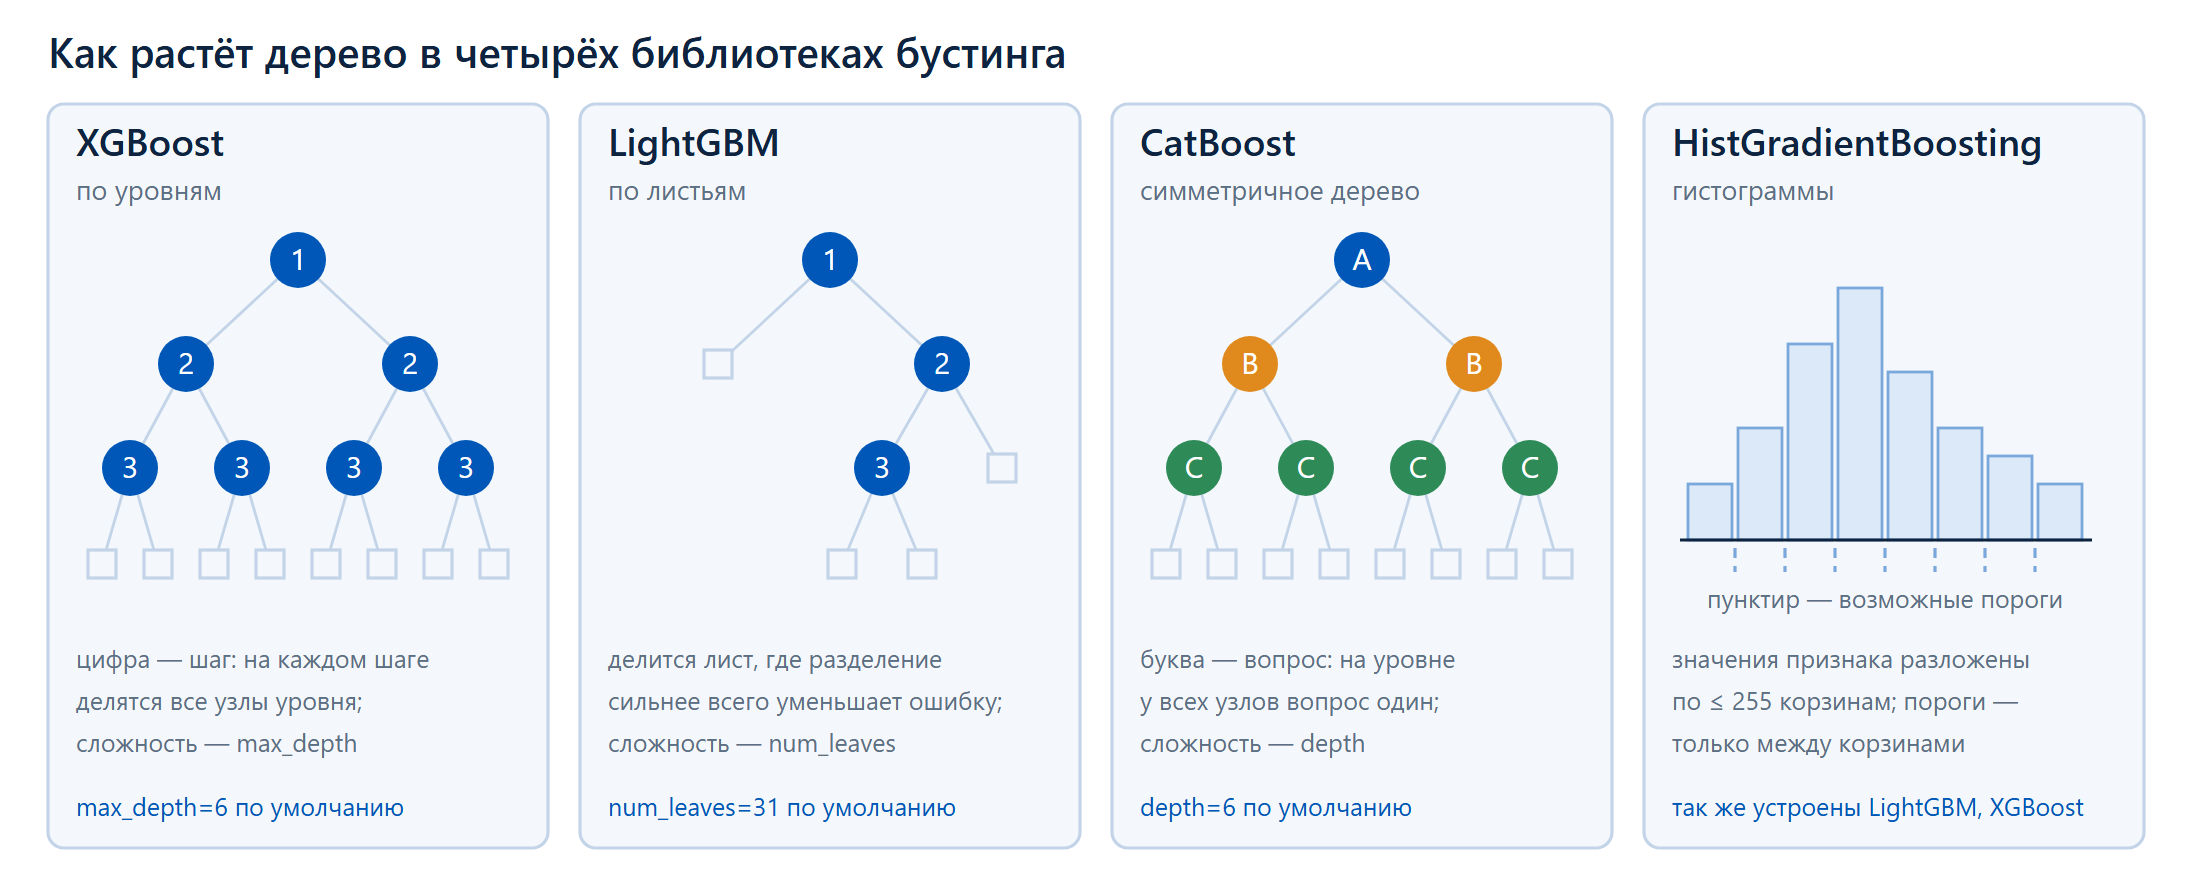

**XGBoost** (2014) — `XGBRegressor`, `XGBClassifier`. Дерево растёт по
уровням: на каждом шаге делятся все узлы уровня, сложность задаёт
глубина. Главные параметры: `n_estimators` (по умолчанию 100),
`learning_rate` (0,3 — высокий), `max_depth` (6), `min_child_weight`,
`subsample`, `colsample_bytree`, `reg_lambda`. *Когда брать:* проверенный
стандарт с большим сообществом; уже используется в компании.

**LightGBM** (2016, Microsoft) — `LGBMRegressor`, `LGBMClassifier`. Дерево
растёт по листьям: каждый раз делится тот лист, где разделение сильнее всего
уменьшает ошибку, поэтому сложность задают числом листьев. Пороги ищет
по гистограммам. Главные параметры: `n_estimators` (100),
`learning_rate` (0,1), `num_leaves` (31), `min_child_samples` (20),
`subsample` с `subsample_freq`, `colsample_bytree`, `reg_lambda`.
*Когда брать:* большие данные, важна скорость обучения.

**CatBoost** (2017, Яндекс) — `CatBoostRegressor`, `CatBoostClassifier`.
Симметричные деревья: на всём уровне один и тот же вопрос. С признаками
CatBoost работает так:

* числовые признаки, как и другие библиотеки, заранее раскладывает по
  корзинам (по умолчанию до 254 границ) и ищет пороги только между ними;
* категориальный признак всего с двумя значениями превращает в признак
  из нулей и единиц (порог задаёт параметр `one_hot_max_size`);
* остальные категориальные признаки заменяет числом — сглаженной долей
  положительного ответа (в регрессии — средним ответом) среди объектов
  с тем же значением. Чтобы ответ объекта не попал в его же признак,
  объекты выстраиваются в случайном порядке, и для каждого доля
  считается только по объектам, стоящим **раньше** него:
  $$\text{значение} = \frac{\text{сумма ответов у предыдущих объектов с тем же значением} + a\,p}{\text{число таких объектов} + a},$$
  где $p$ — априорное значение (например, общая доля положительного
  ответа), $a$ — его вес. У редкого значения предыдущих объектов мало, и
  число остаётся близким к $p$;
* из категориальных признаков сам строит сочетания — например, «ресурс ×
  отдел» — и кодирует их так же.

Главные параметры: `iterations` — число деревьев (1000),
`learning_rate` (подбирает сам по размеру данных), `depth` (6),
`l2_leaf_reg`, `cat_features`, `loss_function`. *Когда брать:* много
категориальных признаков, особенно с сотнями и тысячами значений; нужен
хороший результат без долгой настройки. Учится медленнее остальных.

**HistGradientBoosting** из `scikit-learn` — `HistGradientBoostingRegressor`,
`HistGradientBoostingClassifier`. Устроен как LightGBM: значения каждого
признака заранее раскладываются по 255 корзинам (гистограмма), и пороги
ищутся только между корзинами, поэтому обучается быстро. Принимает
пропуски и категориальные признаки, но у категориального признака должно
быть не больше 255 значений. Главные параметры: `max_iter` — число
деревьев (100), `learning_rate` (0,1), `max_leaf_nodes` (31),
`min_samples_leaf` (20), `l2_regularization`, `loss`. Ранняя остановка
включается сама, если объектов больше 10 000. *Когда брать:* небольшая
задача, нужно обойтись одной `scikit-learn` без установки пакетов.

После настройки качество у библиотек обычно близкое, поэтому выбор чаще
решают размер данных, категориальные признаки и скорость обучения. Ниже
это видно на четырёх кейсах: маленькие данные (страховка), десятки тысяч
объектов (звонки банка), признаки с тысячами значений (заявки на доступ)
и сотни тысяч объектов (задержки рейсов).

## Маленькие данные: бустинги переобучаются

Вернёмся к страховке: обучающих клиентов всего 802. Так бывает часто:
новый продукт, редкое событие, дорогие данные. Обучим четыре бустинга
с параметрами по умолчанию. Чтобы видеть переобучение, считаем MAE не
только на валидации, но и на обучающих клиентах: если на обучении ошибка
намного меньше, чем на валидации, модель запомнила обучающих клиентов.

* `HistGradientBoostingRegressor`, `LGBMRegressor`, `XGBRegressor`,
  `CatBoostRegressor` — бустинги для регрессии из четырёх библиотек;
* случайность в обучении фиксирует параметр `random_state=SEED`,
  у CatBoost он называется `random_seed=SEED`;
* служебные сообщения при обучении отключают `verbose=-1` у LightGBM и
  `verbose=0` у CatBoost.

### Задание 3.1
1. Заполните словарь `BOOSTERS`: под каждым ключом — модель регрессии
   из соответствующей библиотеки с параметрами по умолчанию,
   с зафиксированной случайностью и отключёнными служебными сообщениями.
2. Обучите каждую модель из `BOOSTERS` на обучающих клиентах страховки
   и запишите её MAE на обучающих клиентах в `mae_fit[name]`,
   на валидации — в `mae_val[name]`. Ячейка добавит к ним лес из части 2 и
подобранное дерево из части 1 и нарисует обе ошибки для каждой модели.

In [ ]:
BOOSTERS = {
    "HistGradientBoosting": ...,  # TODO
    "LightGBM": ...,  # TODO
    "XGBoost": ...,  # TODO
    "CatBoost": ...,  # TODO
}
mae_fit, mae_val = {}, {}
for name, model in BOOSTERS.items():
    # TODO
    raise NotImplementedError("замените эту строку своим решением")

## ── для сравнения: лес и дерево ────────────────────────────────────
for name, model in [("случайный лес", forest_ins), ("подобранное дерево", tree_best)]:
    mae_fit[name] = mean_absolute_error(y_train, model.predict(X_train))
    mae_val[name] = mean_absolute_error(y_valid, model.predict(X_valid))

print(f"   {'модель':<22}{'MAE на обучении':>17}{'MAE на валидации':>19}")
for name in mae_val:
    print(f"   {name:<22}{money(mae_fit[name]):>17}{money(mae_val[name]):>19}")

## ── график ─────────────────────────────────────────────────────────
names = list(mae_val)
place = np.arange(len(names))
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.barh(place - 0.2, [mae_fit[k] / 1000 for k in names], height=0.4, color=GREY, label="на обучении")
ax.barh(place + 0.2, [mae_val[k] / 1000 for k in names], height=0.4, color=BLUE, label="на валидации")
ax.set_yticks(place, names)
ax.invert_yaxis()
ax.set_xlabel("MAE, тыс. $")
ax.set_title("Параметры по умолчанию на 802 клиентах")
ax.set_xlim(0, 5)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0)
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(all(k in mae_val for k in BOOSTERS) and all(mae_fit[k] < mae_val[k] for k in BOOSTERS),
      "для каждой модели из BOOSTERS — MAE на обучающих и на валидационных клиентах")

Серые столбики — ошибка на обучающих клиентах, синие — на валидации.
У всех четырёх бустингов ошибка на обучении в разы меньше, чем на
валидации. Сильнее всех XGBoost: на обучении он ошибается всего на
0,3 тысячи долларов, а на валидации на 3,0 тысячи — почти запомнил
обучающих клиентов, и на новых это не помогает. На валидации все четыре
бустинга (2,97–3,12 тысячи) уступают лесу (2,83 тысячи). Лес тоже хорошо
помнит обучающих клиентов, но усреднение не даёт переобучению испортить
прогноз.

### Как переобучение растёт с числом деревьев

Посмотрим, как ошибка меняется с каждым новым деревом, у всех четырёх
бустингов: по 1000 деревьев, остальные параметры по умолчанию. Каждая
библиотека умеет считать качество после каждого дерева, но записывается
это по-разному:

* LightGBM: `fit(X, y, eval_set=[(X_1, y_1), (X_2, y_2)],
  eval_names=["обучение", "валидация"], eval_metric="l1")` (`"l1"` — это
  MAE); ошибки после каждого дерева лежат
  в `модель.evals_result_["обучение"]["l1"]` и `["валидация"]["l1"]`;
* XGBoost: `XGBRegressor(..., eval_metric="mae")`, затем `fit(X, y,
  eval_set=[...], verbose=False)`; ошибки — в
  `модель.evals_result()["validation_0"]["mae"]` и `["validation_1"]`;
* CatBoost: `CatBoostRegressor(..., eval_metric="MAE")`, затем `fit(X, y,
  eval_set=[...], use_best_model=False)`; ошибки — в
  `модель.get_evals_result()["validation_0"]["MAE"]` и `["validation_1"]`;
* HistGradientBoosting: `модель.staged_predict(X)` выдаёт прогнозы после
  1, 2, 3, … деревьев, MAE по ним считаем сами; `early_stopping=False`
  отключает раннюю остановку.

In [ ]:
TREES = 1000
EVAL = [(X_train, y_train), (X_valid, y_valid)]
CURVES = {}                             # библиотека -> (MAE на обучении, MAE на валидации) после каждого дерева

## ── LightGBM ───────────────────────────────────────────────────────
model = LGBMRegressor(n_estimators=TREES, verbose=-1, random_state=SEED)
model.fit(X_train, y_train, eval_set=EVAL, eval_names=["обучение", "валидация"], eval_metric="l1")
CURVES["LightGBM"] = (model.evals_result_["обучение"]["l1"], model.evals_result_["валидация"]["l1"])

## ── XGBoost ────────────────────────────────────────────────────────
model = XGBRegressor(n_estimators=TREES, eval_metric="mae", random_state=SEED)
model.fit(X_train, y_train, eval_set=EVAL, verbose=False)
CURVES["XGBoost"] = (model.evals_result()["validation_0"]["mae"], model.evals_result()["validation_1"]["mae"])

## ── CatBoost ───────────────────────────────────────────────────────
model = CatBoostRegressor(iterations=TREES, eval_metric="MAE", verbose=0, random_seed=SEED)
model.fit(X_train, y_train, eval_set=EVAL, use_best_model=False)
CURVES["CatBoost"] = (model.get_evals_result()["validation_0"]["MAE"],
                      model.get_evals_result()["validation_1"]["MAE"])

## ── HistGradientBoosting ───────────────────────────────────────────
model = HistGradientBoostingRegressor(max_iter=TREES, early_stopping=False, random_state=SEED)
model.fit(X_train, y_train)
CURVES["HistGradientBoosting"] = ([mean_absolute_error(y_train, p) for p in model.staged_predict(X_train)],
                                  [mean_absolute_error(y_valid, p) for p in model.staged_predict(X_valid)])

## ── графики ────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(10, 6.4), sharex=True, sharey=True)
for ax, (name, (fit_curve, val_curve)) in zip(axes.flat, CURVES.items()):
    trees = np.arange(1, len(val_curve) + 1)
    best = int(np.argmin(val_curve))
    ax.plot(trees, np.array(fit_curve) / 1000, color=GREY, label="на обучении")
    ax.plot(trees, np.array(val_curve) / 1000, color=BLUE, label="на валидации")
    ax.axvline(best + 1, color=RED, ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(name, fontsize=11)
    print(f"   {name:<22} лучшая MAE на валидации {money(val_curve[best])} на {best + 1:4d}-м дереве; "
          f"после {TREES}: {money(val_curve[-1])}, на обучении {money(fit_curve[-1])}")
for ax in axes[1]:
    ax.set_xlabel("деревьев (логарифмическая шкала)")
for ax in axes[:, 0]:
    ax.set_ylabel("MAE, тыс. $")
axes[0, 0].set_ylim(0, 6)
axes[0, 0].legend()
plt.show()

У всех четырёх кривые расходятся: ошибка на обучении падает почти до
нуля, а на валидации после минимума (красный пунктир) растёт. Различается
скорость. XGBoost с темпом обучения 0,3 доходит до минимума уже на 13-м
дереве, а к 1000-му почти запоминает обучающих клиентов: ошибка на
обучении 16 долларов. LightGBM и HistGradientBoosting с темпом 0,1
устроены похоже и ведут себя почти одинаково: минимум на 40–50-м дереве,
к 1000-му ошибка на валидации растёт с 2,9 до 3,6–3,7 тысячи. CatBoost
переобучается медленнее всех: минимум только на 212-м дереве, и дальше
ошибка почти не растёт. Для 802 объектов он сам выбрал маленький темп
обучения, а его симметричные деревья проще обычных.

Вывод для маленьких данных: бустингу нужны небольшой темп обучения,
простые деревья и ранняя остановка — её разберём на звонках банка. Без
настройки надёжнее лес или CatBoost.

## Функция ошибки — главный фактор качества на этих данных

Все модели выше учились, уменьшая квадратичную ошибку, а качество мы
меряем средней абсолютной ошибкой (MAE). Это разные цели. Если для
группы клиентов надо назвать одно число-прогноз, то наименьшую
квадратичную ошибку даёт **среднее** расходов группы, а наименьшую MAE —
**медиана**: такое число, что половина клиентов группы потратила меньше
него, а половина — больше. Посмотрим на одну группу — некурящих клиентов
от 40 до 49 лет.

In [ ]:
## ── одна группа: некурящие 40–49 лет ───────────────────────────────
group = y[nonsmoker & clients["возраст"].between(40, 49)].to_numpy()
mean, median = group.mean(), np.median(group)
print(f"Некурящих 40–49 лет: {len(group)}")
print(f"   среднее расходов   {money(mean)}   MAE, если прогнозировать всем среднее:  "
      f"{money(np.abs(group - mean).mean())}")
print(f"   медиана расходов   {money(median)}   MAE, если прогнозировать всем медиану:  "
      f"{money(np.abs(group - median).mean())}")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots()
ax.hist(group / 1000, bins=40, color=GREY)
ax.axvline(median / 1000, color=GREEN, lw=2, label=f"медиана {median / 1000:.1f} тыс. $".replace(".", ","))
ax.axvline(mean / 1000, color=RED, lw=2, label=f"среднее {mean / 1000:.1f} тыс. $".replace(".", ","))
ax.set_xlabel("расходы за год, тыс. $")
ax.set_ylabel("клиентов")
ax.set_title("Немного крупных счетов сдвигают среднее вправо")
ax.legend()
plt.show()

У большинства клиентов группы расходы лежат в узкой полосе, но у части
они в разы выше: кто-то в этом году серьёзно лечился. Эти крупные счета
сдвигают среднее вправо, а медиану почти не двигают. Модель, обученная
на квадратичной ошибке, прогнозирует примерно среднее и поэтому для
большинства клиентов завышает расходы. Если качество меряют MAE,
выгоднее прогнозировать медиану. Отсюда правило: **функцию ошибки, на
которой учится модель, выбирают под метрику качества**.

Три функции ошибки, которые встречались на лекциях, — на рисунке ниже;
по горизонтали ошибка прогноза $e$ = прогноз − ответ:

* квадратичная $e^2$ растёт быстро и сильно штрафует крупные ошибки;
* абсолютная $|e|$ растёт равномерно;
* функция Хьюбера с порогом $\delta$: для малых ошибок ($|e| \le \delta$)
  — как квадратичная, для больших — как абсолютная.

In [ ]:
## ── три функции ошибки ─────────────────────────────────────────────
e = np.linspace(-3, 3, 301)
delta = 1.0
huber = np.where(np.abs(e) <= delta, e ** 2 / 2, delta * (np.abs(e) - delta / 2))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(e, e ** 2 / 2, color=RED, lw=2, label="квадратичная, $e^2/2$")
ax.plot(e, np.abs(e), color=GREEN, lw=2, label="абсолютная, $|e|$")
ax.plot(e, huber, color=BLUE, lw=2.5, ls="--", label=f"Хьюбера, $\\delta$ = {delta:g}")
ax.axvspan(-delta, delta, color=BLUE, alpha=0.06)
ax.set_xlabel("ошибка прогноза e")
ax.set_ylabel("штраф")
ax.set_ylim(0, 4)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

Функцию ошибки в каждой библиотеке выбирает свой параметр:

* LightGBM: `LGBMRegressor(objective="regression")` — квадратичная (по
  умолчанию), `"l1"` — абсолютная, `"huber"` — Хьюбера с порогом `alpha`;
* XGBoost: `XGBRegressor(objective="reg:squarederror")` (по умолчанию),
  `"reg:absoluteerror"`, `"reg:pseudohubererror"`;
* CatBoost: `CatBoostRegressor(loss_function="RMSE")` (по умолчанию),
  `"MAE"`, `"Huber:delta=…"`;
* HistGradientBoosting: `loss="squared_error"` (по умолчанию),
  `"absolute_error"`.

### Задание 3.2
Допишите создание моделей в двух циклах:

* LightGBM с функцией ошибки `objective` из цикла и параметрами
  `n_estimators=300`, `learning_rate=0.05`, `num_leaves=8`,
  `min_child_samples=30`, `verbose=-1`, `random_state=SEED`;
* CatBoost с функцией ошибки `loss` из цикла, остальные параметры — по
  умолчанию, `verbose=0`, `random_seed=SEED`.

Ячейка обучит модели и запишет MAE каждой на валидации в словарь
`loss_mae`.

In [ ]:
loss_mae = {}
for objective in ["regression", "l1"]:
    model = LGBMRegressor(...)  # TODO
    model.fit(X_train, y_train)
    loss_mae[f"LightGBM, {objective}"] = mean_absolute_error(y_valid, model.predict(X_valid))
for loss in ["RMSE", "MAE"]:
    model = CatBoostRegressor(...)  # TODO
    model.fit(X_train, y_train)
    loss_mae[f"CatBoost, {loss}"] = mean_absolute_error(y_valid, model.predict(X_valid))

print("MAE на валидации:")
for name, value in loss_mae.items():
    print(f"   {name:<22} {money(value)}")

## ── самопроверка ───────────────────────────────────────────────────
check(loss_mae["LightGBM, l1"] < loss_mae["LightGBM, regression"]
      and loss_mae["CatBoost, MAE"] < loss_mae["CatBoost, RMSE"] - 300,
      "у каждой библиотеки — две модели: с квадратичной и с абсолютной функцией ошибки")

Абсолютная функция ошибки вместо квадратичной уменьшает MAE LightGBM
с 2,96 до 2,49 тысячи долларов, CatBoost — с 2,97 до 2,13 тысячи. Это
больше, чем дал бы подбор остальных параметров, и намного больше разницы
между библиотеками.

Осторожно с функцией Хьюбера в LightGBM: её порог `alpha` задаётся
в единицах ответа и по умолчанию равен 0,9. Для расходов в тысячи
долларов это порог в 90 центов: почти любая ошибка попадает
в «абсолютную» часть, а шаги обучения получаются крошечными. Проверьте
сами: `objective="huber"` без `alpha` даёт ошибку в разы больше.

| Бустинг на маленьких данных | |
|---|---|
| **что происходит** | с параметрами по умолчанию все четыре библиотеки переобучаются; лес надёжнее |
| **что делать** | упростить деревья, уменьшить темп обучения, использовать раннюю остановку |
| **CatBoost** | из бустингов меньше всех переобучается без настройки, но учится медленнее |
| **главный фактор** | функция ошибки под метрику: `objective` / `loss_function` / `loss` |

## Десятки тысяч объектов: настройка бустинга на звонках банка

Вернёмся к звонкам банка из части 2: 27 тысяч обучающих клиентов. На
таких данных бустинг обычно лучше леса, но только если правильно
выбраны темп обучения, число деревьев и сложность деревьев. Разберём эти
параметры на LightGBM, затем посмотрим на категориальные признаки и
на XGBoost.

Бустингам категориальные признаки можно подавать без превращения
в признаки из нулей и единиц: LightGBM, XGBoost и HistGradientBoosting
принимают столбцы типа `category` и сами решают, как группировать
значения при разделении (XGBoost — если указать `enable_categorical=True`,
HistGradientBoosting — `categorical_features="from_dtype"`). Подготовим
таблицу `B_cat`: те же признаки без длительности звонка, категориальные —
с типом `category`.

In [ ]:
## ── категориальные признаки с типом category ───────────────────────
B_cat = bank_features.drop(columns=["длительность_звонка"])
B_cat[BANK_CAT] = B_cat[BANK_CAT].astype("category")
print(f"Признаков в B_cat: {B_cat.shape[1]}, из них категориальных: {len(BANK_CAT)}")

* `LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=31,
  min_child_samples=20, verbose=-1, random_state=SEED)` — LightGBM для
  классификации; здесь выписаны значения по умолчанию:
  * `learning_rate` — темп обучения $\eta$, `n_estimators` — число
    деревьев; они работают в паре;
  * `num_leaves` — сколько листьев в дереве;
  * `min_child_samples` — меньше скольких объектов в листе быть не может;
  * `subsample` вместе с `subsample_freq=1` — какую долю строк брать для
    каждого дерева, `colsample_bytree` — какую долю признаков;
  * `reg_lambda` — штраф за большие значения в листьях.

In [ ]:
## ── LightGBM по умолчанию ──────────────────────────────────────────
start = time.time()
lgbm_default = LGBMClassifier(verbose=-1, random_state=SEED).fit(B_cat.loc[bank_train], y_bank_train)
seconds = time.time() - start
auc_lgbm_default = roc_auc_score(y_bank_valid, lgbm_default.predict_proba(B_cat.loc[bank_valid])[:, 1])
print("AUC на валидации:")
print(f"   LightGBM по умолчанию   {auc_lgbm_default:.4f}   (обучение {seconds:.1f} с)")
print(f"   лучший лес из части 2   {auc_forest_best:.4f}   (обучение {forest_seconds:.1f} с)")

На 27 тысячах клиентов параметры LightGBM по умолчанию уже разумны: он
обгоняет настроенный лес и учится в разы быстрее. Посмотрим, что делают
параметры. Обучим по 1000 деревьев с темпом 0,1 при трёх уровнях
сложности деревьев и нарисуем AUC на обучении и на валидации после
каждого дерева (`eval_metric="auc"`).

In [ ]:
## ── три уровня сложности деревьев ──────────────────────────────────
SETTINGS = [("сложные: 127 листьев, от 5 клиентов", 127, 5),
            ("средние: 16 листьев, от 100 клиентов", 16, 100),
            ("простые: 4 листа, от 100 клиентов", 4, 100)]
B_EVAL = [(B_cat.loc[bank_train], y_bank_train), (B_cat.loc[bank_valid], y_bank_valid)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (name, leaves, child) in zip(axes, SETTINGS):
    model = LGBMClassifier(n_estimators=1000, learning_rate=0.1, num_leaves=leaves,
                           min_child_samples=child, verbose=-1, random_state=SEED)
    model.fit(B_cat.loc[bank_train], y_bank_train, eval_set=B_EVAL, eval_names=["обучение", "валидация"],
              eval_metric="auc")
    fit_curve, val_curve = model.evals_result_["обучение"]["auc"], model.evals_result_["валидация"]["auc"]
    best = int(np.argmax(val_curve))
    ax.plot(range(1, 1001), fit_curve, color=GREY, label="на обучении")
    ax.plot(range(1, 1001), val_curve, color=BLUE, label="на валидации")
    ax.axvline(best + 1, color=RED, ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("деревьев")
    print(f"   {name:<38} лучший AUC на валидации {max(val_curve):.4f} на {best + 1:4d}-м дереве, "
          f"после 1000: {val_curve[-1]:.4f} (на обучении {fit_curve[-1]:.3f})")
axes[0].set_ylabel("AUC")
axes[0].set_ylim(0.7, 1.01)
axes[0].legend()
plt.show()

Слева сложные деревья: AUC на обучении доходит до 1,0 — модель
запомнила каждого клиента, — а на валидации максимум около 0,807 уже на
28-м дереве, к 1000-му AUC падает до 0,77. Посередине то же, но
медленнее: лучшее — около 0,815 на сотом с небольшим дереве. Справа
простые деревья почти не переобучаются, но и лучший AUC ниже, около
0,809, и его приходится ждать сотни деревьев. Признак переобучения —
расходящиеся кривые: на обучении AUC растёт, на валидации падает.

Сложность деревьев и число деревьев связаны: чем сложнее деревья, тем
раньше надо остановиться. Угадывать момент остановки не нужно:

* `callbacks=[early_stopping(200, verbose=False)]` в `fit` вместе
  с `eval_set` — ранняя остановка: после каждого дерева считать качество
  на **последней** таблице из `eval_set` и остановиться, если 200 деревьев
  подряд не улучшили его. Лучшее число деревьев сохраняется
  в `модель.best_iteration_`, и `predict_proba` дальше сам использует
  только их.

### Задание 3.3
Для каждого темпа обучения из списка `RATES` обучите LightGBM на
обучающих клиентах банка с ранней остановкой: `n_estimators=5000` (с
запасом), качество при остановке — AUC на валидации. Ячейка сохранит
лучшее число деревьев, AUC на валидации и время обучения для каждого
темпа.

In [ ]:
RATES = [0.3, 0.1, 0.03, 0.01]
stopped, best_trees, best_auc, rate_seconds = {}, {}, {}, {}
for rate in RATES:
    model = LGBMClassifier(n_estimators=5000, learning_rate=rate, verbose=-1, random_state=SEED)
    start = time.time()
    # TODO
    raise NotImplementedError("замените эту строку своим решением")
    rate_seconds[rate] = time.time() - start
    stopped[rate] = model
    best_trees[rate] = model.best_iteration_
    best_auc[rate] = roc_auc_score(y_bank_valid, model.predict_proba(B_cat.loc[bank_valid])[:, 1])

print(f"   {'темп обучения':<15}{'лучшее число деревьев':>23}{'AUC на валидации':>18}{'обучение':>10}")
for rate in RATES:
    print(f"   {rate:<15g}{best_trees[rate]:>23d}{best_auc[rate]:>18.4f}{rate_seconds[rate]:>8.1f} с")

## ── график ─────────────────────────────────────────────────────────
rates = np.array(RATES)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(rates, [best_trees[r] for r in RATES], "o-", color=BLUE, lw=2, label="лучшее число деревьев")
axes[0].plot(rates, best_trees[0.1] * 0.1 / rates, ls="--", color=GREY, label="обратная пропорциональность")
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].set_xlabel("темп обучения (логарифмическая шкала)")
axes[0].set_ylabel("деревьев (логарифмическая шкала)")
axes[0].set_title("Меньше темп — больше деревьев", fontsize=11)
axes[0].legend(fontsize=9)
axes[1].plot(rates, [best_auc[r] for r in RATES], "o-", color=RED, lw=2)
axes[1].set_xscale("log")
axes[1].set_xlabel("темп обучения (логарифмическая шкала)")
axes[1].set_ylabel("AUC на валидации")
axes[1].set_ylim(0.78, 0.83)
axes[1].set_title("Качество почти не зависит от темпа", fontsize=11)
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(best_trees[0.3] < best_trees[0.1] < best_trees[0.03] < best_trees[0.01]
      and min(best_auc.values()) > 0.79,
      "для каждого темпа обучения — своя ранняя остановка по AUC на валидации")

При темпе обучения 0,3 лучшее число деревьев — 5, при 0,1 — 81, при
0,03 — 249, при 0,01 — 811. На левом графике обе оси логарифмические, и
точки легли вдоль серой пунктирной линии обратной пропорциональности:
уменьшили темп в 3 раза — деревьев понадобилось примерно в 3 раза больше.
Произведение «темп × число деревьев» почти постоянно (около 8): модель
проходит примерно один и тот же путь, только меньшими шагами. Выпадает
лишь темп 0,3: шаги так велики, что лучшая точка достигается уже на
пятом дереве. Качество (правый график) меняется только в третьем знаке:
лучший AUC — у темпа 0,03, темп 0,01 не лучше, а учится вдвое дольше.

Тонкость: здесь одна и та же валидация и останавливает обучение, и
оценивает качество, поэтому эти AUC немного завышены. Честную оценку
даст тест в конце кейса.

### Задание 3.4
С темпом обучения 0,1 и ранней остановкой по AUC на валидации обучите
LightGBM для каждой пары значений `num_leaves` из списка `NUM_LEAVES` и
`min_child_samples` из списка `MIN_CHILD`. Запишите AUC на валидации
в `leaf_grid[i, j]`, а лучшее число деревьев — в `trees_grid[i, j]`:
строка `i` — `NUM_LEAVES[i]`, столбец `j` — `MIN_CHILD[j]`.

In [ ]:
NUM_LEAVES = [4, 16, 63, 255]
MIN_CHILD = [5, 100, 400]
leaf_grid = np.zeros((len(NUM_LEAVES), len(MIN_CHILD)))
trees_grid = np.zeros_like(leaf_grid, dtype=int)
for i, leaves in enumerate(NUM_LEAVES):
    for j, child in enumerate(MIN_CHILD):
        # TODO
        raise NotImplementedError("замените эту строку своим решением")

print("AUC на валидации (в скобках — лучшее число деревьев):")
print(f"   {'min_child_samples →':<20}" + "".join(f"{child:>15}" for child in MIN_CHILD))
for leaves, row, trees in zip(NUM_LEAVES, leaf_grid, trees_grid):
    print(f"   {f'num_leaves={leaves}':<20}" + "".join(f"{a:>8.4f} ({t:4d})" for a, t in zip(row, trees)))
best_i, best_j = np.unravel_index(np.argmax(leaf_grid), leaf_grid.shape)
best_num_leaves, best_child = NUM_LEAVES[best_i], MIN_CHILD[best_j]
print(f"Лучшая пара: num_leaves={best_num_leaves}, min_child_samples={best_child}")

## ── график ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for j, (child, color) in enumerate(zip(MIN_CHILD, [RED, BLUE, GREEN])):
    label = f"min_child_samples={child}"
    axes[0].plot(NUM_LEAVES, leaf_grid[:, j], "o-", color=color, lw=2, label=label)
    axes[1].plot(NUM_LEAVES, trees_grid[:, j], "o-", color=color, lw=2, label=label)
for ax in axes:
    ax.set_xscale("log", base=2)
    ax.set_xticks(NUM_LEAVES, [str(v) for v in NUM_LEAVES])
    ax.set_xlabel("num_leaves — листьев в дереве")
axes[0].set_ylabel("AUC на валидации")
axes[0].set_ylim(0.78, 0.83)
axes[0].set_title("Качество почти одинаково", fontsize=11)
axes[1].set_yscale("log")
axes[1].set_yticks([20, 50, 100, 200, 500], ["20", "50", "100", "200", "500"])
axes[1].set_ylabel("лучшее число деревьев")
axes[1].set_title("Сложнее деревья — меньше их нужно", fontsize=11)
axes[1].legend(fontsize=9)
plt.show()

## ── самопроверка ───────────────────────────────────────────────────
check(leaf_grid.min() > 0.78 and (trees_grid > 0).all() and trees_grid[0].mean() > trees_grid[-1].mean(),
      "для каждой пары — своя ранняя остановка; в trees_grid — best_iteration_")

Главная мысль задания — на правом графике: чем сложнее деревья, тем
меньше их нужно. Деревьям из 4 листьев нужны сотни деревьев, из 255
листьев — несколько десятков. Ранняя остановка сама подстраивает число
деревьев под сложность, и поэтому качество (левый график) почти не
меняется: почти все AUC лежат в пределах 0,807–0,815 — разница в третьем
знаке, того же порядка, что и от случайности разбиения на обучение и
валидацию. Выделяются только самые сложные деревья — 255 листьев при 5 и
100 клиентах в листе (0,796 и 0,803): они запоминают мелкие группы
клиентов, и ранняя остановка уже не спасает. Вывод: если число деревьев
подобрано ранней остановкой, сложность деревьев влияет на качество
слабо; крайних значений стоит избегать.

Остальные параметры — доли строк и признаков для каждого дерева и
штраф — проверим на лучшей паре.

In [ ]:
## ── доли строк и признаков, штраф — поверх лучшей пары ─────────────
EXTRAS = [("без добавок", {}),
          ("70 % строк на дерево", {"subsample": 0.7, "subsample_freq": 1}),
          ("70 % признаков на дерево", {"colsample_bytree": 0.7}),
          ("штраф reg_lambda=10", {"reg_lambda": 10})]
for name, extra in EXTRAS:
    model = LGBMClassifier(n_estimators=5000, learning_rate=0.1, num_leaves=best_num_leaves,
                           min_child_samples=best_child, verbose=-1, random_state=SEED, **extra)
    model.fit(B_cat.loc[bank_train], y_bank_train, eval_set=[(B_cat.loc[bank_valid], y_bank_valid)],
              eval_metric="auc", callbacks=[early_stopping(200, verbose=False)])
    auc = roc_auc_score(y_bank_valid, model.predict_proba(B_cat.loc[bank_valid])[:, 1])
    print(f"   {name:<26} AUC {auc:.4f}, деревьев {model.best_iteration_}")

Ни одна добавка заметно не помогла. Доли строк и признаков и штраф
полезны, когда признаков много или данные шумные; здесь признаков всего
15, а лучшая пара уже сдерживает переобучение.

**Как настраивать бустинг:**

1. Взять темп обучения 0,1 и раннюю остановку на валидации — число
   деревьев подберётся само.
2. Подобрать сложность деревьев: `num_leaves` и `min_child_samples`
   (в XGBoost — `max_depth` и `min_child_weight`, в CatBoost — `depth`).
   Кривые на обучении и валидации расходятся — деревья упростить; кривые
   рядом, а качество низкое — усложнить.
3. Если признаков много или данные шумные — доли строк и признаков на
   дерево и штраф `reg_lambda`.
4. Для итоговой модели уменьшить темп обучения в 3–5 раз: деревьев станет
   больше, качество — чуть выше.

## Как подавать категориальные признаки

Сравним три способа подать одни и те же категориальные признаки
LightGBM:

* `B_cat` — тип `category`: LightGBM сам решает, как группировать
  значения;
* `B_codes` — номер значения вместо значения (`столбец.cat.codes`):
  обычные числа, номера идут по алфавиту;
* `B_onehot` — признаки из нулей и единиц из части 2.

Заодно проверим HistGradientBoosting из `scikit-learn` на `B_cat`.

In [ ]:
## ── номера значений вместо значений ────────────────────────────────
B_codes = B_cat.copy()
for col in BANK_CAT:
    B_codes[col] = B_cat[col].cat.codes

## ── LightGBM с тремя способами подать категории ────────────────────
for name, table in [("тип category (B_cat)", B_cat), ("номера значений (B_codes)", B_codes),
                    ("нули и единицы (B_onehot)", B_onehot)]:
    model = LGBMClassifier(n_estimators=5000, learning_rate=0.05, verbose=-1, random_state=SEED)
    model.fit(table.loc[bank_train], y_bank_train, eval_set=[(table.loc[bank_valid], y_bank_valid)],
              eval_metric="auc", callbacks=[early_stopping(200, verbose=False)])
    auc = roc_auc_score(y_bank_valid, model.predict_proba(table.loc[bank_valid])[:, 1])
    print(f"   LightGBM, {name:<30} AUC {auc:.4f}")

## ── HistGradientBoosting на типе category ──────────────────────────
start = time.time()
hgb = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=SEED)
hgb.fit(B_cat.loc[bank_train], y_bank_train)
auc = roc_auc_score(y_bank_valid, hgb.predict_proba(B_cat.loc[bank_valid])[:, 1])
print(f"   HistGradientBoosting, тип category       AUC {auc:.4f}, деревьев {hgb.n_iter_}, "
      f"обучение {time.time() - start:.1f} с")

Тип `category` лучше остальных способов. С номерами значений дерево
режет категории в алфавитном порядке: вопрос «месяц ≤ 5» объединяет
август, апрель, декабрь, июль, июнь и май, и на осмысленную группу
месяцев уходит несколько разделений. С типом `category` LightGBM сам
упорядочивает значения по тому, как они связаны с ответом, — приём,
который был на лекции. HistGradientBoosting из `scikit-learn` с типом
`category` дал меньше, около 0,80, — на уровне настроенного леса. У него
сама включилась ранняя остановка (объектов больше 10 000): для неё он
отложил 10 % обучающих клиентов и остановился на 48-м дереве.

## XGBoost: те же параметры, другие значения по умолчанию

* `XGBClassifier(n_estimators=100, learning_rate=0.3, max_depth=6,
  tree_method="hist", enable_categorical=True, random_state=SEED)` —
  XGBoost; первые три — значения по умолчанию. Дерево растёт по уровням,
  поэтому сложность задаёт `max_depth`. Категориальные признаки
  принимает, только если явно указать `enable_categorical=True`.
* Ранняя остановка в XGBoost задаётся при создании модели:
  `XGBClassifier(..., early_stopping_rounds=200, eval_metric="auc")`,
  а в `fit` передают `eval_set=[(X_val, y_val)]` и `verbose=False`.
  Лучшее число деревьев — в `модель.best_iteration`.

### Задание 3.5
Обучите на обучающих клиентах банка XGBoost с темпом обучения 0,05,
глубиной 4 и ранней остановкой по AUC на валидации (`n_estimators=5000`
с запасом, остальные параметры — как у модели по умолчанию в ячейке) и
сохраните его в `xgb_tuned`. Ячейка сравнит его с XGBoost по умолчанию.

In [ ]:
## ── по умолчанию ───────────────────────────────────────────────────
xgb_default = XGBClassifier(tree_method="hist", enable_categorical=True, random_state=SEED)
xgb_default.fit(B_cat.loc[bank_train], y_bank_train)
auc_xgb_default = roc_auc_score(y_bank_valid, xgb_default.predict_proba(B_cat.loc[bank_valid])[:, 1])

## ── с настройкой ───────────────────────────────────────────────────
# TODO
raise NotImplementedError("замените эту строку своим решением")
auc_xgb_tuned = roc_auc_score(y_bank_valid, xgb_tuned.predict_proba(B_cat.loc[bank_valid])[:, 1])

print(f"XGBoost по умолчанию:  AUC {auc_xgb_default:.4f}")
print(f"XGBoost с настройкой:  AUC {auc_xgb_tuned:.4f}, деревьев {xgb_tuned.best_iteration}")

## ── самопроверка ───────────────────────────────────────────────────
check(auc_xgb_tuned > auc_xgb_default + 0.01,
      "темп обучения 0,05, глубина 4 и ранняя остановка по AUC на валидации")

С параметрами по умолчанию XGBoost даёт AUC около 0,79: темп 0,3
слишком велик, и сто деревьев глубины 6 проскакивают лучшую точку.
С темпом 0,05, глубиной 4 и ранней остановкой — около 0,81. У XGBoost
значения по умолчанию — не готовый ответ: темп обучения и раннюю
остановку задают всегда. Настроенные XGBoost и LightGBM дают почти одно и
то же качество, и выбирают между ними скорее по скорости и по тому, что
уже используется в компании.

## Деньги: скольким клиентам звонить

Модель упорядочила клиентов, а решение — где остановить обзвон.
**Экономика** (в жизни её дают маркетинг и финансы): звонок стоит банку
**5 €**, открытый вклад приносит **50 €**. Звоним сверху вниз по оценке
модели; если позвонить $k$ первым клиентам, прибыль равна
$50 \times (\text{согласившихся среди них}) - 5 \times k$. Оценки берём
у LightGBM с темпом обучения 0,03 из задания 3.3.

* `np.argsort(-оценки)` — номера клиентов в порядке убывания оценки;
* `np.cumsum(массив)` — накопленные суммы: элемент `k − 1` — сумма первых
  `k` элементов.

In [ ]:
COST, GAIN = 5, 50
prob_final = stopped[0.03].predict_proba(B_cat.loc[bank_valid])[:, 1]

order = np.argsort(-prob_final)                     # сначала самые перспективные
agreed_top = np.cumsum(y_bank_valid[order])         # согласившихся среди первых k, для каждого k
calls = np.arange(1, len(y_bank_valid) + 1)         # k: сколько звонков сделано
profit = GAIN * agreed_top - COST * calls           # прибыль для каждого k

best_k = int(np.argmax(profit)) + 1
call_share = best_k / len(y_bank_valid)
print(f"Звонить всем:                 прибыль {euro(profit[-1])}")
print(f"Звонить лучшим {100 * call_share:4.0f} % клиентов: прибыль {euro(profit[best_k - 1])}, "
      f"звонков {best_k}")

## ── график ─────────────────────────────────────────────────────────
fig, ax = plt.subplots()
ax.plot(100 * calls / len(calls), profit / 1000, color=BLUE, lw=2)
ax.axvline(100 * call_share, color=RED, ls="--", lw=1.2)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel("кому звоним, % клиентов (по убыванию оценки)")
ax.set_ylabel("прибыль, тыс. €")
ax.set_title("Звонить всем — не лучший план")
plt.show()

Обзвон всех приносит около 7,7 тысячи евро: доля согласившихся, 11,7 %,
лишь чуть выше точки безубыточности $5 / 50 = 10\,\%$. Если звонить
примерно четверти клиентов с самыми высокими оценками, прибыль около
25 тысяч евро — втрое больше при вчетверо меньшем числе звонков.

**Тест — один раз.** Обучаем итоговую модель на обучении и валидации
вместе — с темпом обучения 0,03 и найденным числом деревьев, — проверяем
AUC на тесте и применяем решение «звонить лучшей доле клиентов».

In [ ]:
## ── обучение на обучении и валидации вместе ────────────────────────
final = LGBMClassifier(n_estimators=best_trees[0.03], learning_rate=0.03, verbose=-1,
                       random_state=SEED)
final.fit(B_cat.loc[bank_fit], agreed[bank_fit])
prob_test = final.predict_proba(B_cat.loc[bank_test])[:, 1]
y_bank_test = agreed[bank_test].to_numpy()
print(f"AUC на тесте: {roc_auc_score(y_bank_test, prob_test):.4f}")

## ── деньги на тесте ────────────────────────────────────────────────
k_test = int(round(call_share * len(y_bank_test)))
top = np.argsort(-prob_test)[:k_test]
print(f"Звонить всем:                прибыль {euro(GAIN * y_bank_test.sum() - COST * len(y_bank_test))}")
print(f"Звонить лучшим {100 * call_share:.0f} % клиентов: прибыль "
      f"{euro(GAIN * y_bank_test[top].sum() - COST * k_test)}")

На тесте AUC немного ниже, чем на валидации: валидация и останавливала
обучение, и оценивала его, поэтому её оценка была завышена. Решение
«звонить лучшей четверти клиентов» и на новых данных приносит примерно
втрое больше, чем обзвон всех.

| Бустинг на десятках тысяч объектов | |
|---|---|
| **сильные стороны** | обычно лучшее качество на табличных данных; быстро учится; категориальные признаки и пропуски принимает сам |
| **слабые стороны** | без ранней остановки переобучается; параметров много, значения по умолчанию у библиотек разные |
| **главные параметры** | темп обучения и ранняя остановка, затем сложность деревьев |

## Признаки с тысячами значений: когда брать CatBoost

**Кейс — заявки на доступ.** Сотрудник крупной компании просит доступ
к ресурсу — папке, системе, приложению. Сейчас каждую заявку вручную
смотрит руководитель. Если модель надёжно отличает заявки, в которых
откажут, остальные можно одобрять автоматически. **Метрика — ROC-AUC.**

**Данные.** 32 769 заявок сотрудников Amazon — набор Amazon Employee
Access Challenge ([Kaggle, 2013](https://www.kaggle.com/c/amazon-employee-access-challenge)),
он же на openml.org — [openml.org/d/4135](https://www.openml.org/d/4135).
Все девять признаков — **коды**: ресурса, руководителя, отдела,
должности, роли. Числами они только записаны: код 117961 не «больше»
кода 117905. И значений у этих признаков сотни и тысячи. Названия
столбцов переведены на русский, больше ничего не меняли.

In [ ]:
## ── данные ─────────────────────────────────────────────────────────
ACCESS = ("https://raw.githubusercontent.com/Rimest/ml_ai_course_gsb_hse"
          "/main/data/amazon_access.csv")
access = pd.read_csv(ACCESS)
denied = access["отказано"]            # ответ: 1 — в доступе отказали
CODES = [col for col in access.columns if col != "отказано"]

print(f"Заявок: {len(access)}, отказано: {100 * denied.mean():.1f} %")
print("Разных значений у признаков:")
for col in CODES:
    print(f"   {col:<16} {access[col].nunique():5d}")

## ── обучение и валидация ───────────────────────────────────────────
# здесь сравниваем подходы, поэтому теста не откладываем
acc_train, acc_valid = train_test_split(access.index, test_size=0.25, random_state=SEED, stratify=denied)
y_acc_train, y_acc_valid = denied[acc_train].to_numpy(), denied[acc_valid].to_numpy()

## ── три таблицы ────────────────────────────────────────────────────
A_codes = access[CODES]                          # коды как числа
A_cat = access[CODES].astype("category")         # тип category — для LightGBM и XGBoost
A_text = access[CODES].astype(str)               # текст — для CatBoost
ACCESS_RESULTS = {}                              # название -> (AUC на валидации, секунд обучения)

У 7518 ресурсов и 4243 руководителей многие значения встречаются всего
по нескольку раз, а часть — один раз. Именно для таких данных создан
CatBoost. Как описано в начале части 3, он заменяет каждое значение
категориального признака долей отказов, посчитанной только по заявкам,
которые стоят раньше в случайном порядке, сглаживает её к общей доле
отказов и сам строит сочетания признаков, например «ресурс × отдел».
Начнём с него, а затем сравним с моделями, которые уже знаем.

* `CatBoostClassifier(iterations=300, depth=6, cat_features=CODES,
  verbose=0, random_seed=SEED)` — CatBoost для классификации.
  `iterations` — число деревьев, `depth` — глубина (по умолчанию 6),
  `cat_features` — список категориальных признаков; значения в них должны
  быть **текстом** (таблица `A_text`). Темп обучения по умолчанию
  CatBoost подбирает сам.

### Задание 3.6
Для глубины 4 и глубины 6 обучите CatBoost из описания выше на
обучающих заявках таблицы `A_text` и запишите в `ACCESS_RESULTS` под
ключом `f"CatBoost, глубина {depth}"` пару: AUC на валидации и время
обучения в секундах.

In [ ]:
for depth in [4, 6]:
    # TODO
    raise NotImplementedError("замените эту строку своим решением")

for name, (value, seconds) in ACCESS_RESULTS.items():
    print(f"   {name:<28} AUC на валидации {value:.4f}, обучение {seconds:.1f} с")

## ── самопроверка ───────────────────────────────────────────────────
check(all(f"CatBoost, глубина {d}" in ACCESS_RESULTS for d in [4, 6])
      and max(ACCESS_RESULTS[f"CatBoost, глубина {d}"][0] for d in [4, 6]) > 0.88,
      "категориальные признаки для CatBoost — текстом и перечислены в cat_features")

Теперь те же заявки — моделям, которые мы уже знаем: лесу (коды как
числа) и бустингам LightGBM, XGBoost и HistGradientBoosting (тип
`category`).

In [ ]:
## ── знакомые модели ────────────────────────────────────────────────
for name, model, table in [
        ("лес на кодах как числах", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), A_codes),
        ("LightGBM, тип category", LGBMClassifier(verbose=-1, random_state=SEED), A_cat),
        ("XGBoost, тип category", XGBClassifier(tree_method="hist", enable_categorical=True,
                                                 random_state=SEED), A_cat)]:
    start = time.time()
    model.fit(table.loc[acc_train], y_acc_train)
    ACCESS_RESULTS[name] = (roc_auc_score(y_acc_valid, model.predict_proba(table.loc[acc_valid])[:, 1]),
                            time.time() - start)

## ── HistGradientBoosting ───────────────────────────────────────────
try:
    HistGradientBoostingClassifier(categorical_features="from_dtype").fit(A_cat.loc[acc_train], y_acc_train)
except ValueError as error:
    print(f"HistGradientBoosting не принял категории: {str(error)[:80]} …")

## ── сравнение ──────────────────────────────────────────────────────
print("AUC на валидации:")
for name, (value, seconds) in sorted(ACCESS_RESULTS.items(), key=lambda kv: -kv[1][0]):
    print(f"   {name:<28} {value:.4f}   обучение {seconds:.1f} с")

## ── график ─────────────────────────────────────────────────────────
names = sorted(ACCESS_RESULTS, key=lambda k: -ACCESS_RESULTS[k][0])
fig, ax = plt.subplots(figsize=(7.2, 3))
ax.barh(names, [ACCESS_RESULTS[k][0] for k in names],
        color=[BLUE if k.startswith("CatBoost") else GREY for k in names])
ax.set_xlim(0.8, 0.9)
ax.invert_yaxis()
ax.set_xlabel("AUC на валидации")
ax.set_title("Признаки с тысячами значений: CatBoost впереди")
ax.grid(axis="y", alpha=0)
plt.show()

CatBoost даёт AUC 0,892, остальные модели — от 0,854 до 0,866: для AUC
разница в 0,026 большая. HistGradientBoosting категориальные признаки не
принял вовсе: у него ограничение — не больше 255 значений у признака.

**Почему остальные модели хуже.**

* **Лес на кодах как числах** задаёт вопросы вида «ресурс ≤ 25 300», но
  порядок кодов случаен: в одну группу попадают никак не связанные
  ресурсы, и осмысленную группу дерево собирает только из многих
  разделений.
* **LightGBM и XGBoost с типом `category`** в каждом узле упорядочивают
  значения признака по тому, как часто заявкам с этим значением
  отказывали, и ищут лучшую границу в этом порядке. Но у большинства
  значений всего по нескольку заявок, и их доля отказов почти случайна:
  модель группирует значения по шуму и переобучается. Чтобы этого
  избежать, LightGBM объединяет редкие значения в общую группу — и
  информацию о них теряет.
* **CatBoost** считает долю отказов только по предыдущим заявкам и
  сглаживает её к общей доле, поэтому редкое значение получает
  осторожную оценку, а не случайную. Сочетания «ресурс × отдел»,
  «руководитель × роль» добавляют информацию, которой нет в отдельных
  признаках.

Глубина 4 и 6 дали почти одно и то же, а мельче — быстрее. Цена — время:
CatBoost учился в десятки раз дольше LightGBM (7–10 секунд против 0,2).

| CatBoost | |
|---|---|
| **сильные стороны** | категориальные признаки с сотнями и тысячами значений — без утечки и без ручной подготовки; хорош с параметрами по умолчанию |
| **слабые стороны** | учится в разы медленнее LightGBM и XGBoost |
| **главные параметры** | `iterations`, `depth`, `learning_rate`; `loss_function` для регрессии |
| **когда использовать** | много категориальных признаков, особенно с большим числом значений; мало времени на настройку |

## Сотни тысяч объектов: когда брать LightGBM

**Кейс — задержки рейсов.** Авиакомпании и аэропорты хотят заранее
знать, какой рейс задержится, чтобы предупредить пассажиров и
перераспределить экипажи. **Метрика — ROC-AUC.**

**Данные.** 539 383 рейса внутри США — набор airlines с openml.org
([openml.org/d/1169](https://www.openml.org/d/1169), E. Ikonomovska, по
данным конкурса DataExpo 2009). `время_вылета` и `длительность_полёта`
записаны в минутах. Названия столбцов переведены на русский, больше
ничего не меняли. Файл большой — загрузка займёт несколько секунд.

In [ ]:
## ── данные ─────────────────────────────────────────────────────────
FLIGHTS = ("https://raw.githubusercontent.com/Rimest/ml_ai_course_gsb_hse"
           "/main/data/flight_delays.csv")
flights = pd.read_csv(FLIGHTS)
delayed = flights["задержка"]          # ответ: 1 — рейс задержался

F_CAT = ["авиакомпания", "откуда", "куда"]
F_cat = flights.drop(columns=["задержка"])
F_cat[F_CAT] = F_cat[F_CAT].astype("category")
F_codes = F_cat.copy()
for col in F_CAT:
    F_codes[col] = F_cat[col].cat.codes
F_text = F_cat.copy()
F_text[F_CAT] = F_text[F_CAT].astype(str)

## ── обучение и валидация ───────────────────────────────────────────
fl_pool, fl_valid = train_test_split(flights.index, test_size=0.2, random_state=SEED, stratify=delayed)
y_fl_valid = delayed[fl_valid].to_numpy()

print(f"Рейсов: {len(flights)}, задержались {100 * delayed.mean():.1f} %")
print(f"Для обучения: {len(fl_pool)}, валидация: {len(fl_valid)}")
print(f"Аэропортов вылета: {flights['откуда'].nunique()}")
flights.head()

### Сколько данных нужно

Обучим один и тот же LightGBM (500 деревьев, темп обучения 0,1,
63 листа) на первых 25 тысячах, 100 тысячах и всех 431 тысяче рейсов из
`fl_pool` (рейсы там уже перемешаны) и сравним AUC на валидации и время
обучения.

In [ ]:
SIZES = [25_000, 100_000, len(fl_pool)]
size_auc, size_seconds = [], []
for size in SIZES:
    rows = fl_pool[:size]
    start = time.time()
    model = LGBMClassifier(n_estimators=500, learning_rate=0.1, num_leaves=63, verbose=-1,
                           random_state=SEED)
    model.fit(F_cat.loc[rows], delayed[rows])
    size_seconds.append(time.time() - start)
    size_auc.append(roc_auc_score(y_fl_valid, model.predict_proba(F_cat.loc[fl_valid])[:, 1]))

print(f"   {'рейсов в обучении':<20}{'AUC на валидации':>18}{'обучение':>12}")
for size, auc, seconds in zip(SIZES, size_auc, size_seconds):
    print(f"   {size:<20d}{auc:>18.4f}{seconds:>10.1f} с")

С 25 тысяч до 431 тысячи рейсов AUC вырос с 0,67 до 0,73 —
больше, чем дала бы любая настройка параметров. Время обучения растёт
вместе с объёмом, и здесь скорость библиотеки уже важна: каждую идею
придётся проверять на всех данных.

Теперь сравним все библиотеки на одних и тех же 200 тысячах рейсов, по
300 деревьев с темпом обучения 0,1. HistGradientBoosting и лес получают
номера значений категориальных признаков: у аэропортов больше 255
значений.

In [ ]:
## ── пять моделей на 200 тысячах рейсов ─────────────────────────────
rows = fl_pool[:200_000]
RACE = {}
for name, model, table in [
        ("LightGBM", LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=63, verbose=-1,
                                    random_state=SEED), F_cat),
        ("XGBoost", XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist",
                                  enable_categorical=True, random_state=SEED), F_cat),
        ("HistGradientBoosting", HistGradientBoostingClassifier(max_iter=300, early_stopping=False,
                                                                random_state=SEED), F_codes),
        ("CatBoost", CatBoostClassifier(iterations=300, learning_rate=0.1, cat_features=F_CAT, verbose=0,
                                        random_seed=SEED), F_text),
        ("лес, 100 деревьев", RandomForestClassifier(n_estimators=100, min_samples_leaf=20, n_jobs=-1,
                                                     random_state=SEED), F_codes)]:
    start = time.time()
    model.fit(table.loc[rows], delayed[rows])
    seconds = time.time() - start
    RACE[name] = (roc_auc_score(y_fl_valid, model.predict_proba(table.loc[fl_valid])[:, 1]), seconds)
    print(f"   {name:<22} AUC {RACE[name][0]:.4f}, обучение {seconds:5.1f} с")

## ── график ─────────────────────────────────────────────────────────
names = list(RACE)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ax[0].barh(names, [RACE[k][0] for k in names], color=BLUE)
ax[0].set_xlim(0.6, 0.75)
ax[0].set_title("AUC на валидации")
ax[1].barh(names, [RACE[k][1] for k in names], color=GREY)
ax[1].set_title("обучение, секунд")
ax[0].invert_yaxis()
for a in ax:
    a.grid(axis="y", alpha=0)
plt.show()

Качество у всех пяти моделей почти одинаковое, а время обучения разное.
LightGBM, HistGradientBoosting, XGBoost и лес учились около секунды,
CatBoost — в 10–20 раз дольше. В Colab с двумя ядрами процессора все цифры
больше, но соотношение обычно то же. На больших данных выбор библиотеки —
это выбор скорости: чем быстрее обучение, тем больше вариантов признаков
и параметров успеешь проверить. Обычно быстрее всех LightGBM.

| LightGBM | |
|---|---|
| **сильные стороны** | быстрее всех на больших данных; сам принимает категориальные признаки; ранняя остановка встроена |
| **слабые стороны** | на маленьких данных с параметрами по умолчанию переобучается; дерево растёт по листьям, и сложность нужно держать параметрами `num_leaves` и `min_child_samples` |
| **когда использовать** | основной рабочий вариант на таблицах от десятков тысяч объектов |

---
# Когда что брать

| Модель | Когда брать | Когда не брать |
|---|---|---|
| одно дерево | нужны понятные правила и сегменты | нужно точное предсказание: дерево неустойчиво и ступенчато |
| случайный лес | маленькие данные; нет времени на настройку; нужна надёжная точка отсчёта | нужна наилучшая точность; модель должна быть компактной |
| HistGradientBoosting | нельзя ставить пакеты, данные небольшие, у категориальных признаков не больше 255 значений | категориальные признаки с сотнями значений |
| LightGBM | десятки тысяч объектов и больше; важна скорость | очень маленькие данные без настройки |
| XGBoost | то же, что LightGBM; уже используется в компании | без настройки: темп обучения 0,3 по умолчанию слишком велик |
| CatBoost | много категориальных признаков, особенно с тысячами значений; маленькие данные; мало времени на настройку | важна скорость обучения на больших данных |

И для всех ансамблей из деревьев: за пределами обучающих данных они
выдают постоянный прогноз, а функция ошибки, выбранная под метрику, даёт
больше, чем подбор остальных параметров.

# Шпаргалка по параметрам

| Модель | Параметр | Что делает | Если переобучается | Если недообучается |
|---|---|---|---|---|
| дерево | `max_depth` | сколько вопросов подряд | уменьшить | увеличить |
| дерево, лес | `min_samples_leaf` | меньше скольких объектов в листе быть не может | увеличить | уменьшить |
| лес | `n_estimators` | сколько деревьев усреднять | — лес не переобучается от числа деревьев | увеличить |
| лес | `max_features` | доля признаков, случайно выбираемых в каждом узле | уменьшить | увеличить |
| бустинг | `learning_rate` и число деревьев | темп обучения и число шагов | ранняя остановка | больше деревьев |
| LightGBM | `num_leaves`, `min_child_samples` | листьев в дереве, размер листа | уменьшить, увеличить | увеличить, уменьшить |
| XGBoost | `max_depth`, `min_child_weight` | глубина, размер листа | уменьшить, увеличить | увеличить, уменьшить |
| CatBoost | `depth` | глубина симметричного дерева | уменьшить | увеличить |
| HistGradientBoosting | `max_leaf_nodes`, `min_samples_leaf` | листьев в дереве, размер листа | уменьшить, увеличить | увеличить, уменьшить |
| бустинг | `subsample`, `colsample_bytree` | доля строк и признаков на дерево | меньше 1 | 1 |
| бустинг | `reg_lambda` (`l2_leaf_reg` в CatBoost) | штраф за большие значения в листьях | увеличить | уменьшить |
| бустинг | `objective` (`loss_function` в CatBoost, `loss` в scikit-learn) | функция ошибки | — | — выбирают под метрику |

---
# Итоги

| Что | Зачем понадобилось |
|---|---|
| дерево глубины 2, его поля и перебор разделений в корне | как обучается и что хранит дерево |
| признак «курит и ИМТ > 30» в линейной регрессии | дерево само находит сочетания признаков |
| `max_depth` × `min_samples_leaf` | без ограничений дерево запоминает обучающие данные |
| два дерева на бутстрап-выборках, обучение на клиентах моложе 40 лет | слабые стороны дерева: неустойчивость и постоянный прогноз за пределами обучающих данных |
| ИМТ с пропусками | дерево обучается на пропусках без заполнения |
| два леса на бутстрап-выборках | усреднение делает лес устойчивее дерева |
| AUC от числа деревьев, оценка OOB | число деревьев в лесу не подбирают; параметры леса подбирают по OOB без валидации |
| четыре бустинга на 802 клиентах | на маленьких данных бустинги с параметрами по умолчанию переобучаются |
| `objective` / `loss_function` | функция ошибки под метрику — главный фактор качества на страховке |
| кривые обучения и ранняя остановка | видно переобучение; число деревьев подбирается само |
| `num_leaves` × `min_child_samples`, XGBoost по умолчанию | темп обучения и сложность деревьев — главные параметры бустинга |
| CatBoost на кодах и сравнение с другими моделями | признаки с тысячами значений — задача CatBoost |
| рост данных и сравнение библиотек | на больших данных решают объём данных и скорость — LightGBM |
| кривая прибыли | модель упорядочивает клиентов, а сколько звонить — решают деньги |

**Что дальше.** Мы сравнивали модели по одной цифре — MAE или AUC — и
только в кейсе с банком перешли к деньгам. На следующей лекции — как
выбирать метрику так, чтобы она отражала бизнес-результат.